In [1]:
%pip install -q dash dash-ag-grid plotly

Note: you may need to restart the kernel to use updated packages.


In [2]:
#libraries
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from matplotlib.colors import LinearSegmentedColormap
from dash import Dash, html, dcc, callback, Output, Input
import dash_ag_grid as dag
import plotly.express as px
from itertools import combinations

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

# Setting seaborn style
main_color = "#40916C"
colors = ["#1B4332", "#40916C", "#95D5B2", "#F4D35E", "#EE964B"]
sns.set_theme(style="ticks", palette=colors)

<b><font size="6" color="#FAA85E">1.Data Exploration and Initial Analysis</font></b><br>

In [3]:
df_raw = pd.read_csv("data/acdc_dataset.csv", sep=";", index_col="member_id")
df = df_raw.copy()
df_raw.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,...,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,...,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,...,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,...,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,...,False,False,0,False,False,True,False,False,0,335.74


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  str    
 2   industry                     15465 non-null  str    
 3   country                      15035 non-null  str    
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  str    
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  str    
 9   membership_end               15465 non-null  str    
 10  last_badge_swipe             15465 non-null  str    
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_visits     

In [5]:
df_raw.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='str')

In [6]:
df_raw.isna().sum()[lambda s: s > 0]

age                     558
gender                  530
country                 430
plan_tier               105
meeting_room_hours     1298
guest_passes_issued    1271
lifetime_value         1040
dtype: int64

In [7]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


In [8]:
df_raw.describe(include="bool").T

,count,unique,top,freq
is_team_account,15465,2,False,11112
uses_meeting_rooms,15465,2,False,10202
uses_event_space,15465,2,False,13624
uses_guest_passes,15465,2,False,12651
uses_mail_handling,15465,2,False,11901
uses_phone_booths,15465,2,False,11469
uses_day_passes,15465,2,False,12069
uses_storage,15465,2,False,13169
uses_bike_locker,15465,2,False,15439


In [9]:
df_raw.describe(include="str").T
#plan tier should only have 5 unique values
#gender shou have 3: Female, Male, Other

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


<b><font size="6" color="#FAA85E">2.Data Quality Checks</font></b><br>

In [10]:
df['membership_start'] = pd.to_datetime(df["membership_start"], format='mixed')
df['membership_end'] = pd.to_datetime(df["membership_end"], format='mixed')
df['last_badge_swipe'] = pd.to_datetime(df["last_badge_swipe"], format='mixed')

We turned the variable `lifetime_value` to a float. The variable had symbols that made them into an object type.

In [11]:
df["lifetime_value"] = (
    df["lifetime_value"]
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

In [12]:
df_raw["uses_print"].unique()

array([0, 1])

`uses_print` only has the values 1 and 0, so we turn it into a boolean type.

In [13]:
df["uses_print"] = df["uses_print"].astype("bool")
df["uses_print"].dtype

dtype('bool')

In [14]:
#Turning object values to lower case
cols_object = df.select_dtypes(include="str").columns
df[cols_object] = df[cols_object].apply(lambda s: s.str.lower())

print(f"Gender unique values: {df["gender"].unique()}")
print(f"Country unique values: {df["country"].unique()}")
print(f"Plan tier unique values: {df["plan_tier"].unique()}")
print(f"Industry unique values: {df["industry"].unique()}")

Gender unique values: <ArrowStringArray>
['female', 'male', 'f', 'other', nan, ' female', 'm', ' male', ' other', 'o']
Length: 10, dtype: str
Country unique values: <ArrowStringArray>
[       'portugal',              'de',  'united kingdom',           'spain',
         'germany',     'netherlands',          'france',              'pt',
  'other (europe)',        'portucal',               nan,              'uk',
         'ireland',              'ie',       'portugal ',     'deutschland',
            'u.k.',              'gb',              'es',              'nl',
          'españa',          'espana', 'the netherlands',              'fr',
         'holland']
Length: 25, dtype: str
Plan tier unique values: <ArrowStringArray>
[          'flex',       'hot_desk', 'dedicated_desk',      'full_time',
 'private_office',       'hot desk',  'dedicateddesk',              nan,
        'hotdesk',       'fulltime',  'privateoffice',      'full time',
 'dedicated desk', 'private office']
Length: 14,

In [15]:
#Replacing gender values
df["gender"] = df["gender"].replace([" female", "f"], "female")
df["gender"] = df["gender"].replace([" male", "m"], "male")
df["gender"] = df["gender"].replace([" other", "o"], "other")

#Replacing country values
df["country"] = df["country"].replace({
    "portucal":"portugal", "portugal ":"portugal", "pt":"portugal",
    "de":"germany", "deutschland":"germany",
    "uk":"united kingdom", "u.k.":"united kingdom", "gb":"united kingdom",
    "es":"spain", "españa":"spain", "espana":"spain",
    "nl":"netherlands", "the netherlands":"netherlands", "holland":"netherlands",
    "fr":"france",
    "ie":"ireland"})

#Replacing Plan tier values
df["plan_tier"] = df["plan_tier"].replace(["hotdesk", "hot desk"], "hot_desk")
df["plan_tier"] = df["plan_tier"].replace(["dedicateddesk", "dedicated desk"], "dedicated_desk")
df["plan_tier"] = df["plan_tier"].replace(["fulltime", "full time"], "full_time")
df["plan_tier"] = df["plan_tier"].replace(["privateoffice", "private office"], "private_office")

#Replacing Industry values
df["industry"] = df["industry"].replace(["it", "tech"], "information technology")
df["industry"] = df["industry"].replace(["design & creative", "design/creative"], "design and creative")
df["industry"] = df["industry"].replace(["marketing & pr", "marketing/pr"], "marketing and pr")
df["industry"] = df["industry"].replace(["realestate", "real-estate"], "real estate")

df.describe(include="str").T

,count,unique,top,freq
gender,14935,3,female,7867
industry,15465,11,information technology,3559
country,15035,8,portugal,10508
plan_tier,15360,5,flex,5453


In [16]:
df.duplicated().sum()

np.int64(295)

In [17]:
df_nodups = df.drop_duplicates()

In [18]:
bool_cols = ['is_team_account',
 'uses_meeting_rooms',
 'uses_event_space',
 'uses_guest_passes',
 'uses_print',
 'uses_mail_handling',
 'uses_phone_booths',
 'uses_day_passes',
 'uses_storage',
 'uses_bike_locker']

add_ons = [c for c in bool_cols if c != 'is_team_account']

df_nodups['n_add_on'] = df_nodups[add_ons].sum(axis=1)

In [19]:
non_metric_features = ['gender', 'country', 'industry', 'plan_tier', 'is_team_account',
 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes',
 'uses_storage', 'uses_bike_locker']

metric_features = df_nodups.columns.drop(non_metric_features).to_list()

In [20]:
#df_metrics = df_nodups.loc[metric_features]

#neg_counts = (df_metrics < 0).sum()

#print("Variables with negative values:")
#print(neg_counts[neg_counts > 0])

In [21]:
(df_nodups['plan_days_per_week'] > 7).sum()

np.int64(53)

<b><font size="6" color="#FAA85E">3.Metric Features Visualization</font></b><br>

<b><font size="5" color="#FAA85E">3.1. Unvariate Analysis</font></b><br>

<b><font size="4" color="#FAA85E">3.1.1. `age`</font></b><br>

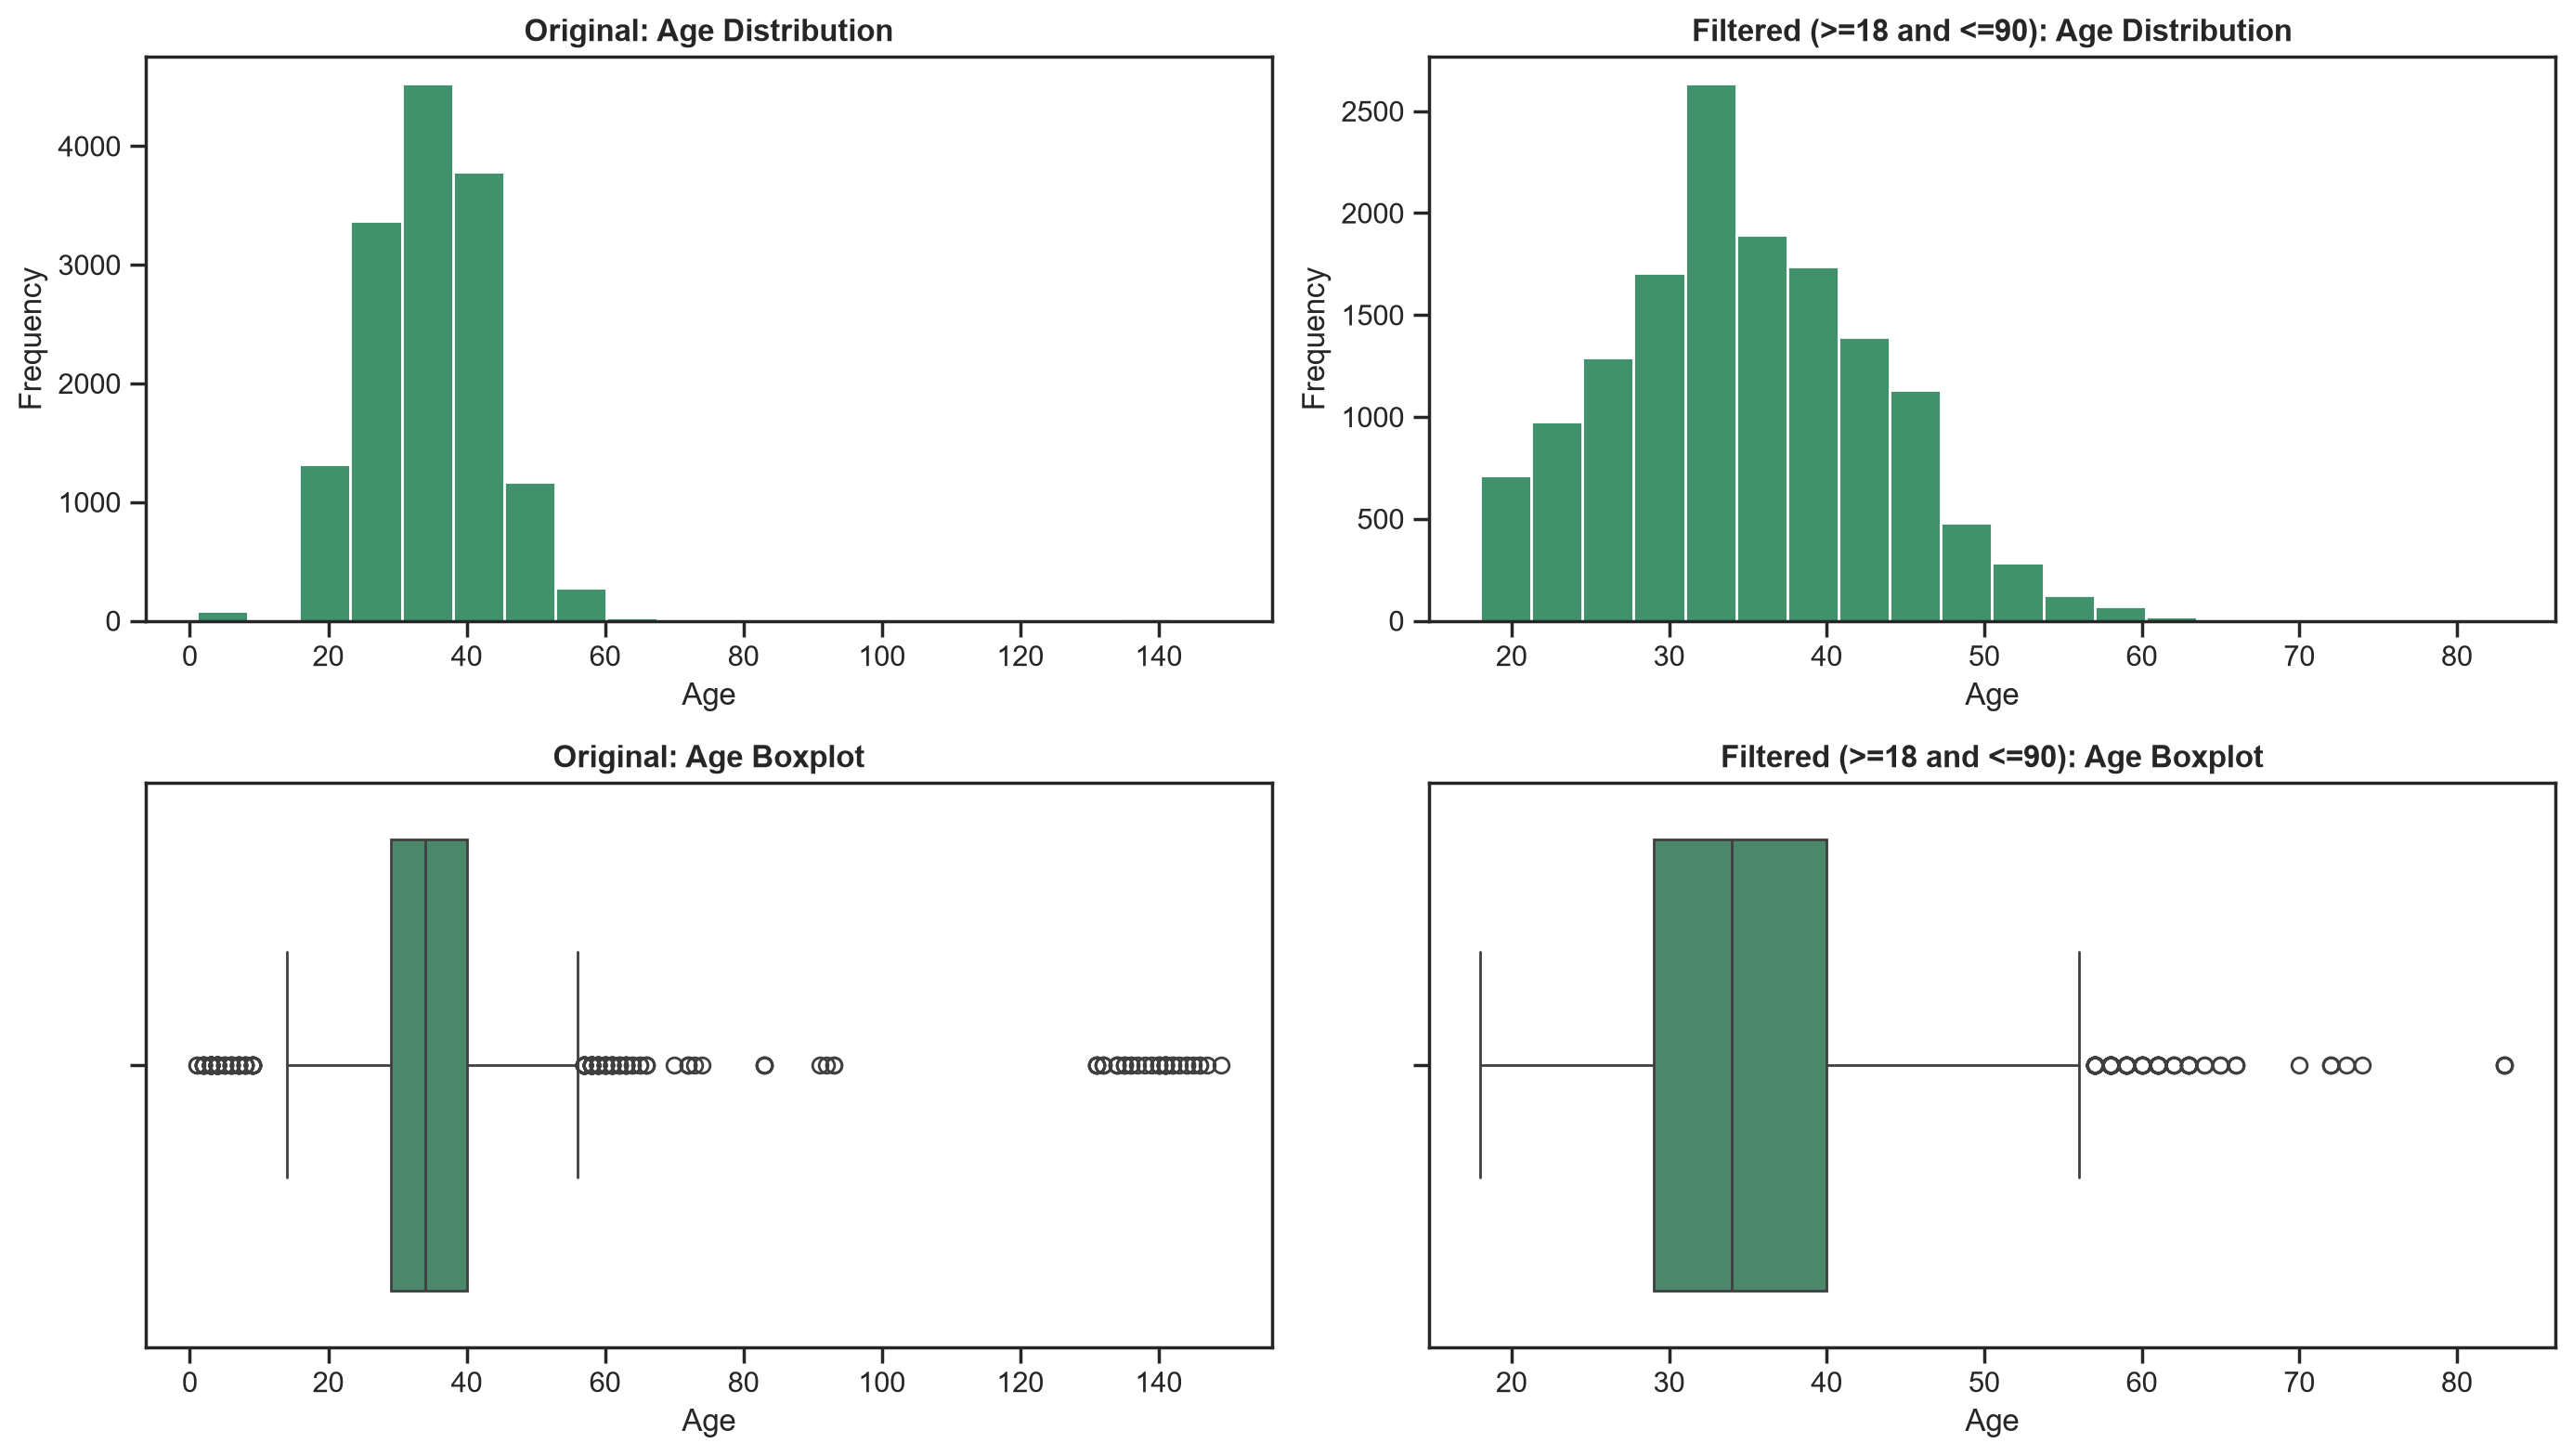

In [22]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, 
        2, 
        figsize=subplot_figsize)

df_age_filtered = df_nodups[(df_nodups["age"] > 17) & (df_nodups["age"] < 91)]

axes[0, 0].hist(df_nodups["age"].dropna(), bins=20, color=main_color)
axes[0, 1].hist(df_age_filtered["age"].dropna(), bins=20, color=main_color)

sns.boxplot(x=df_nodups["age"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_age_filtered["age"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Age Distribution', fontweight="bold") 
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>=18 and <=90): Age Distribution', fontweight="bold") 
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Age Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Age')

axes[1, 1].set_title('Filtered (>=18 and <=90): Age Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Age')

plt.tight_layout()
plt.show()

### 3.1.2. `n_colleagues_on_account`

For this variable, we filtered out the values that are < 0, since they are impossible.

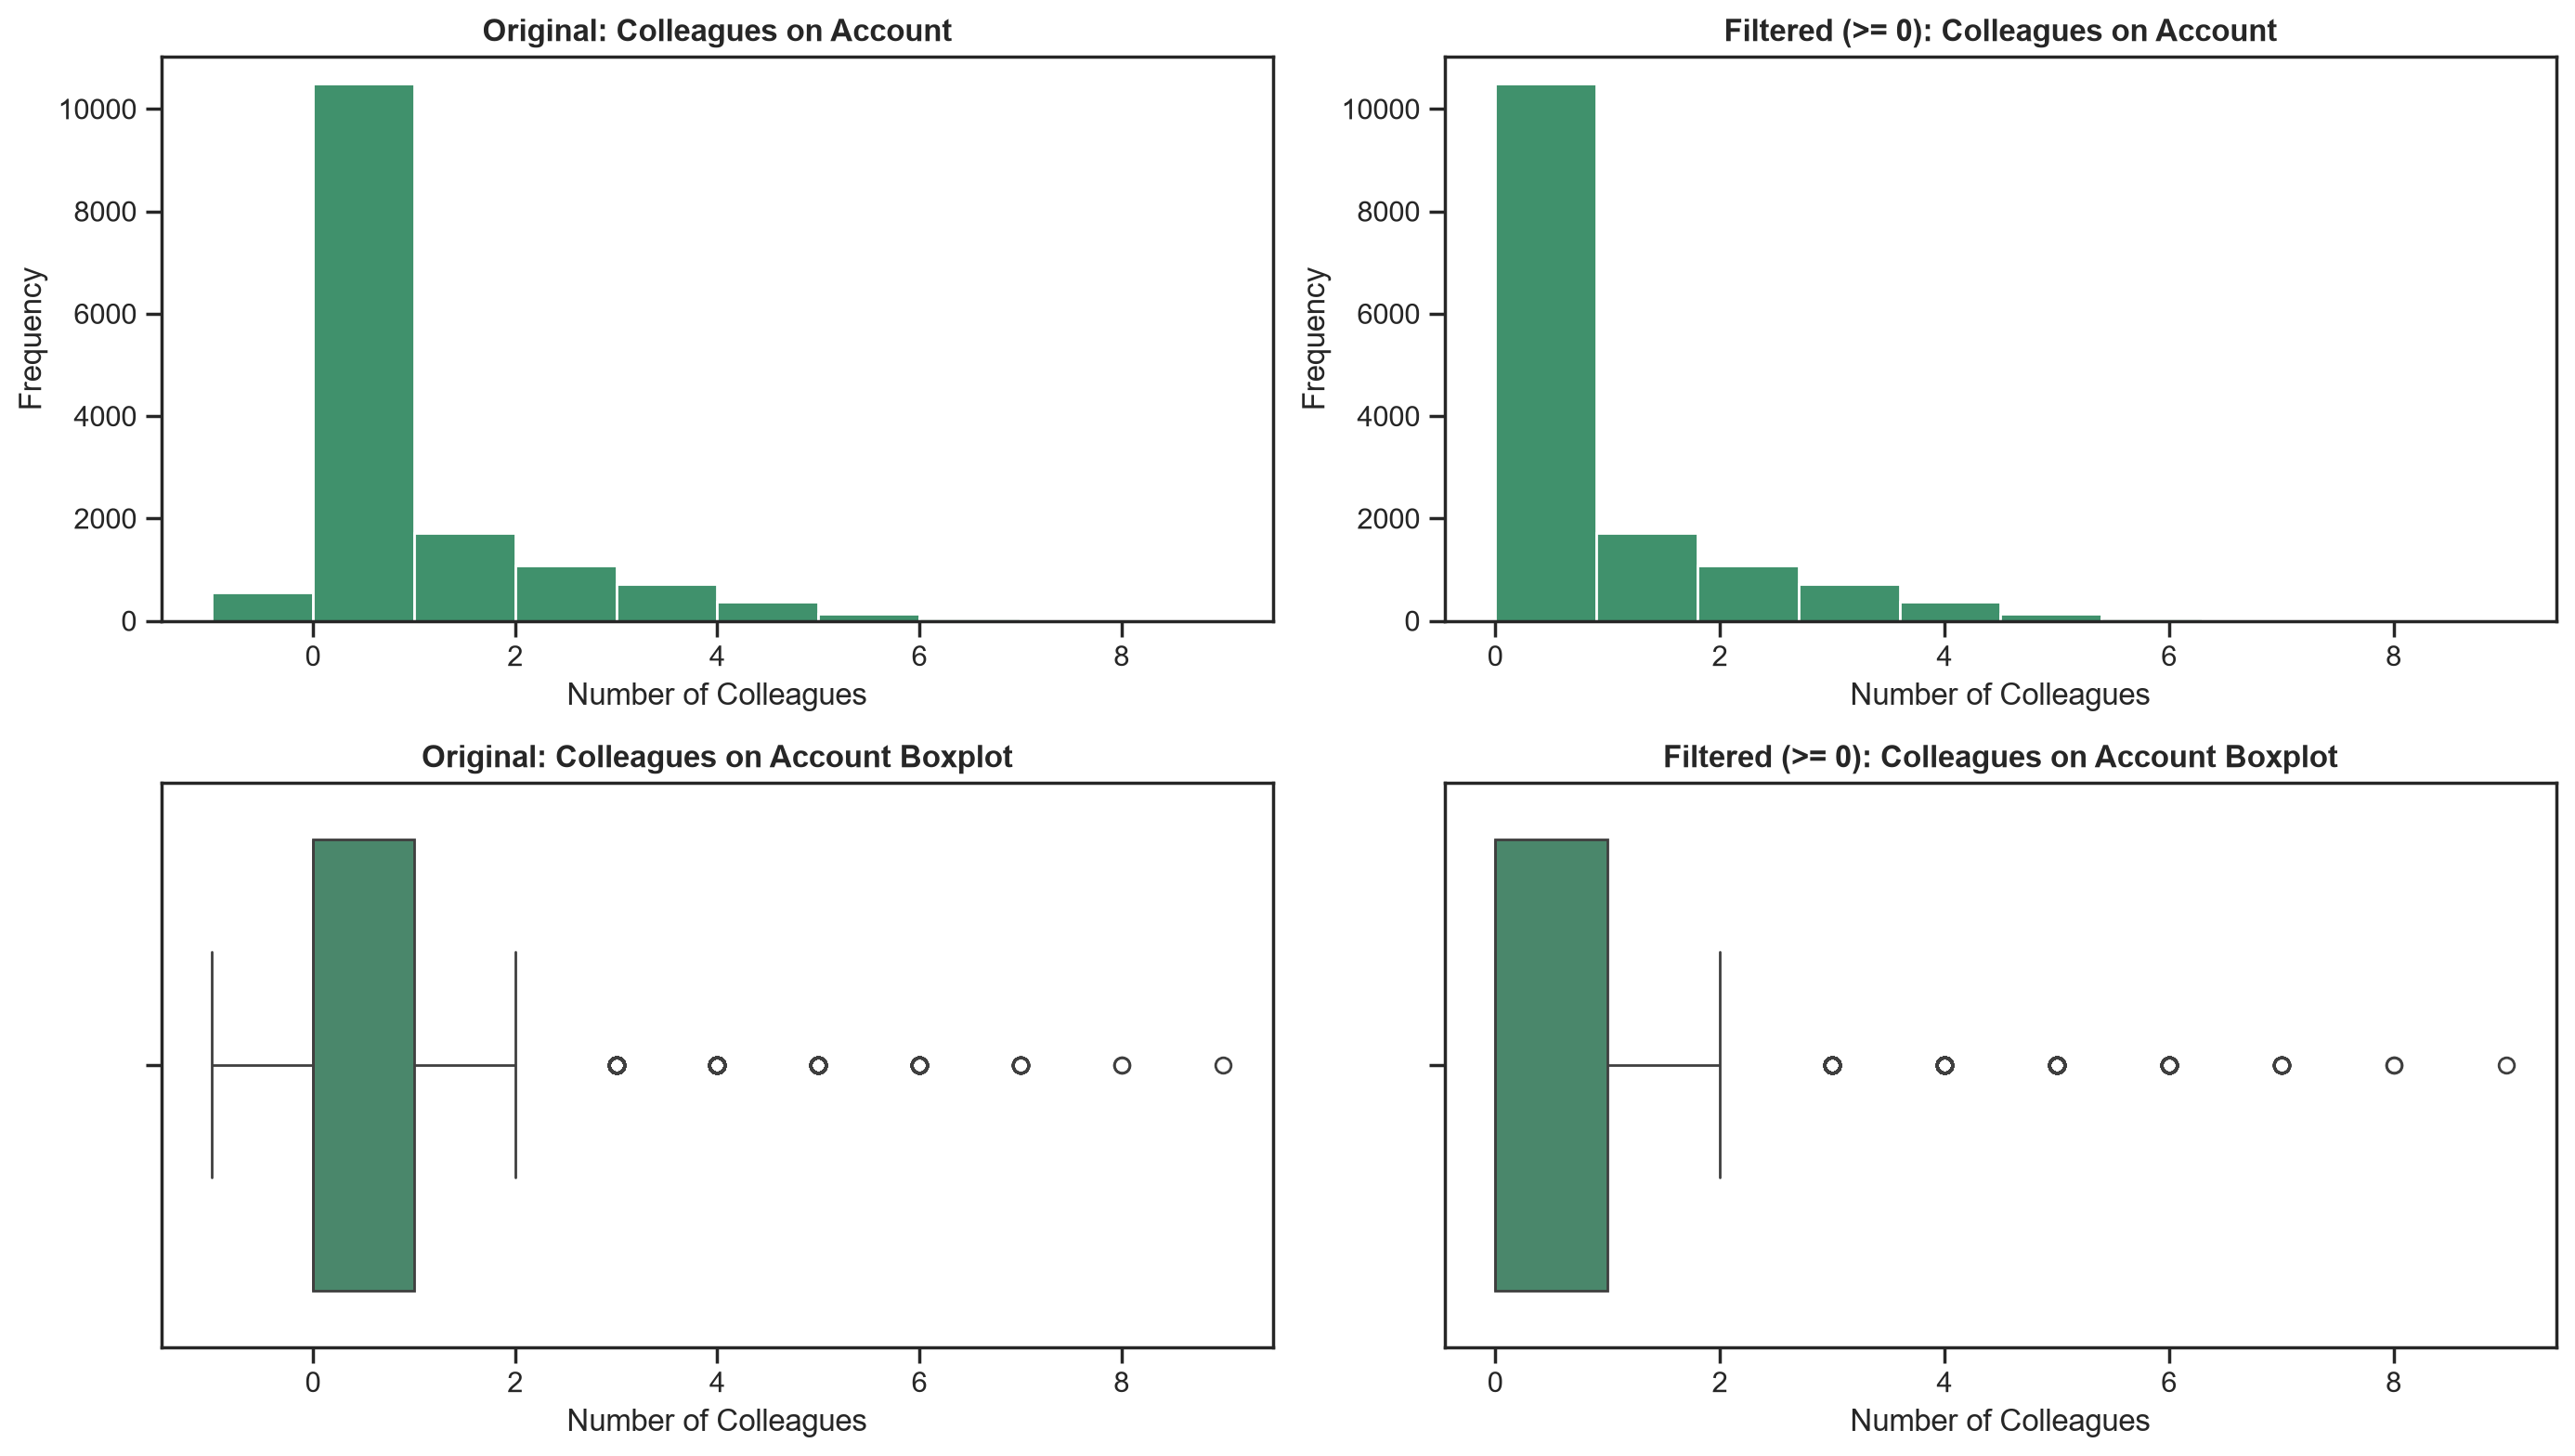

In [23]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, 
        2, 
        figsize=subplot_figsize)

df_colleagues_clean = df_nodups[df_nodups["n_colleagues_on_account"] >= 0]

axes[0, 0].hist(df_nodups["n_colleagues_on_account"].dropna(), bins=10, color=main_color)
axes[0, 1].hist(df_colleagues_clean["n_colleagues_on_account"].dropna(), bins=10, color=main_color)
sns.boxplot(x=df_nodups["n_colleagues_on_account"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_colleagues_clean["n_colleagues_on_account"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Colleagues on Account', fontweight="bold") 
axes[0, 0].set_xlabel('Number of Colleagues')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>= 0): Colleagues on Account', fontweight="bold") 
axes[0, 1].set_xlabel('Number of Colleagues')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Colleagues on Account Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Number of Colleagues')

axes[1, 1].set_title('Filtered (>= 0): Colleagues on Account Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Number of Colleagues')

plt.tight_layout()
plt.show()

### 3.1.3. `plan_days_per_week`

For this variable we filter by the plan days per week that are <= 7, since it is impossible for a week to have more than 7 days.

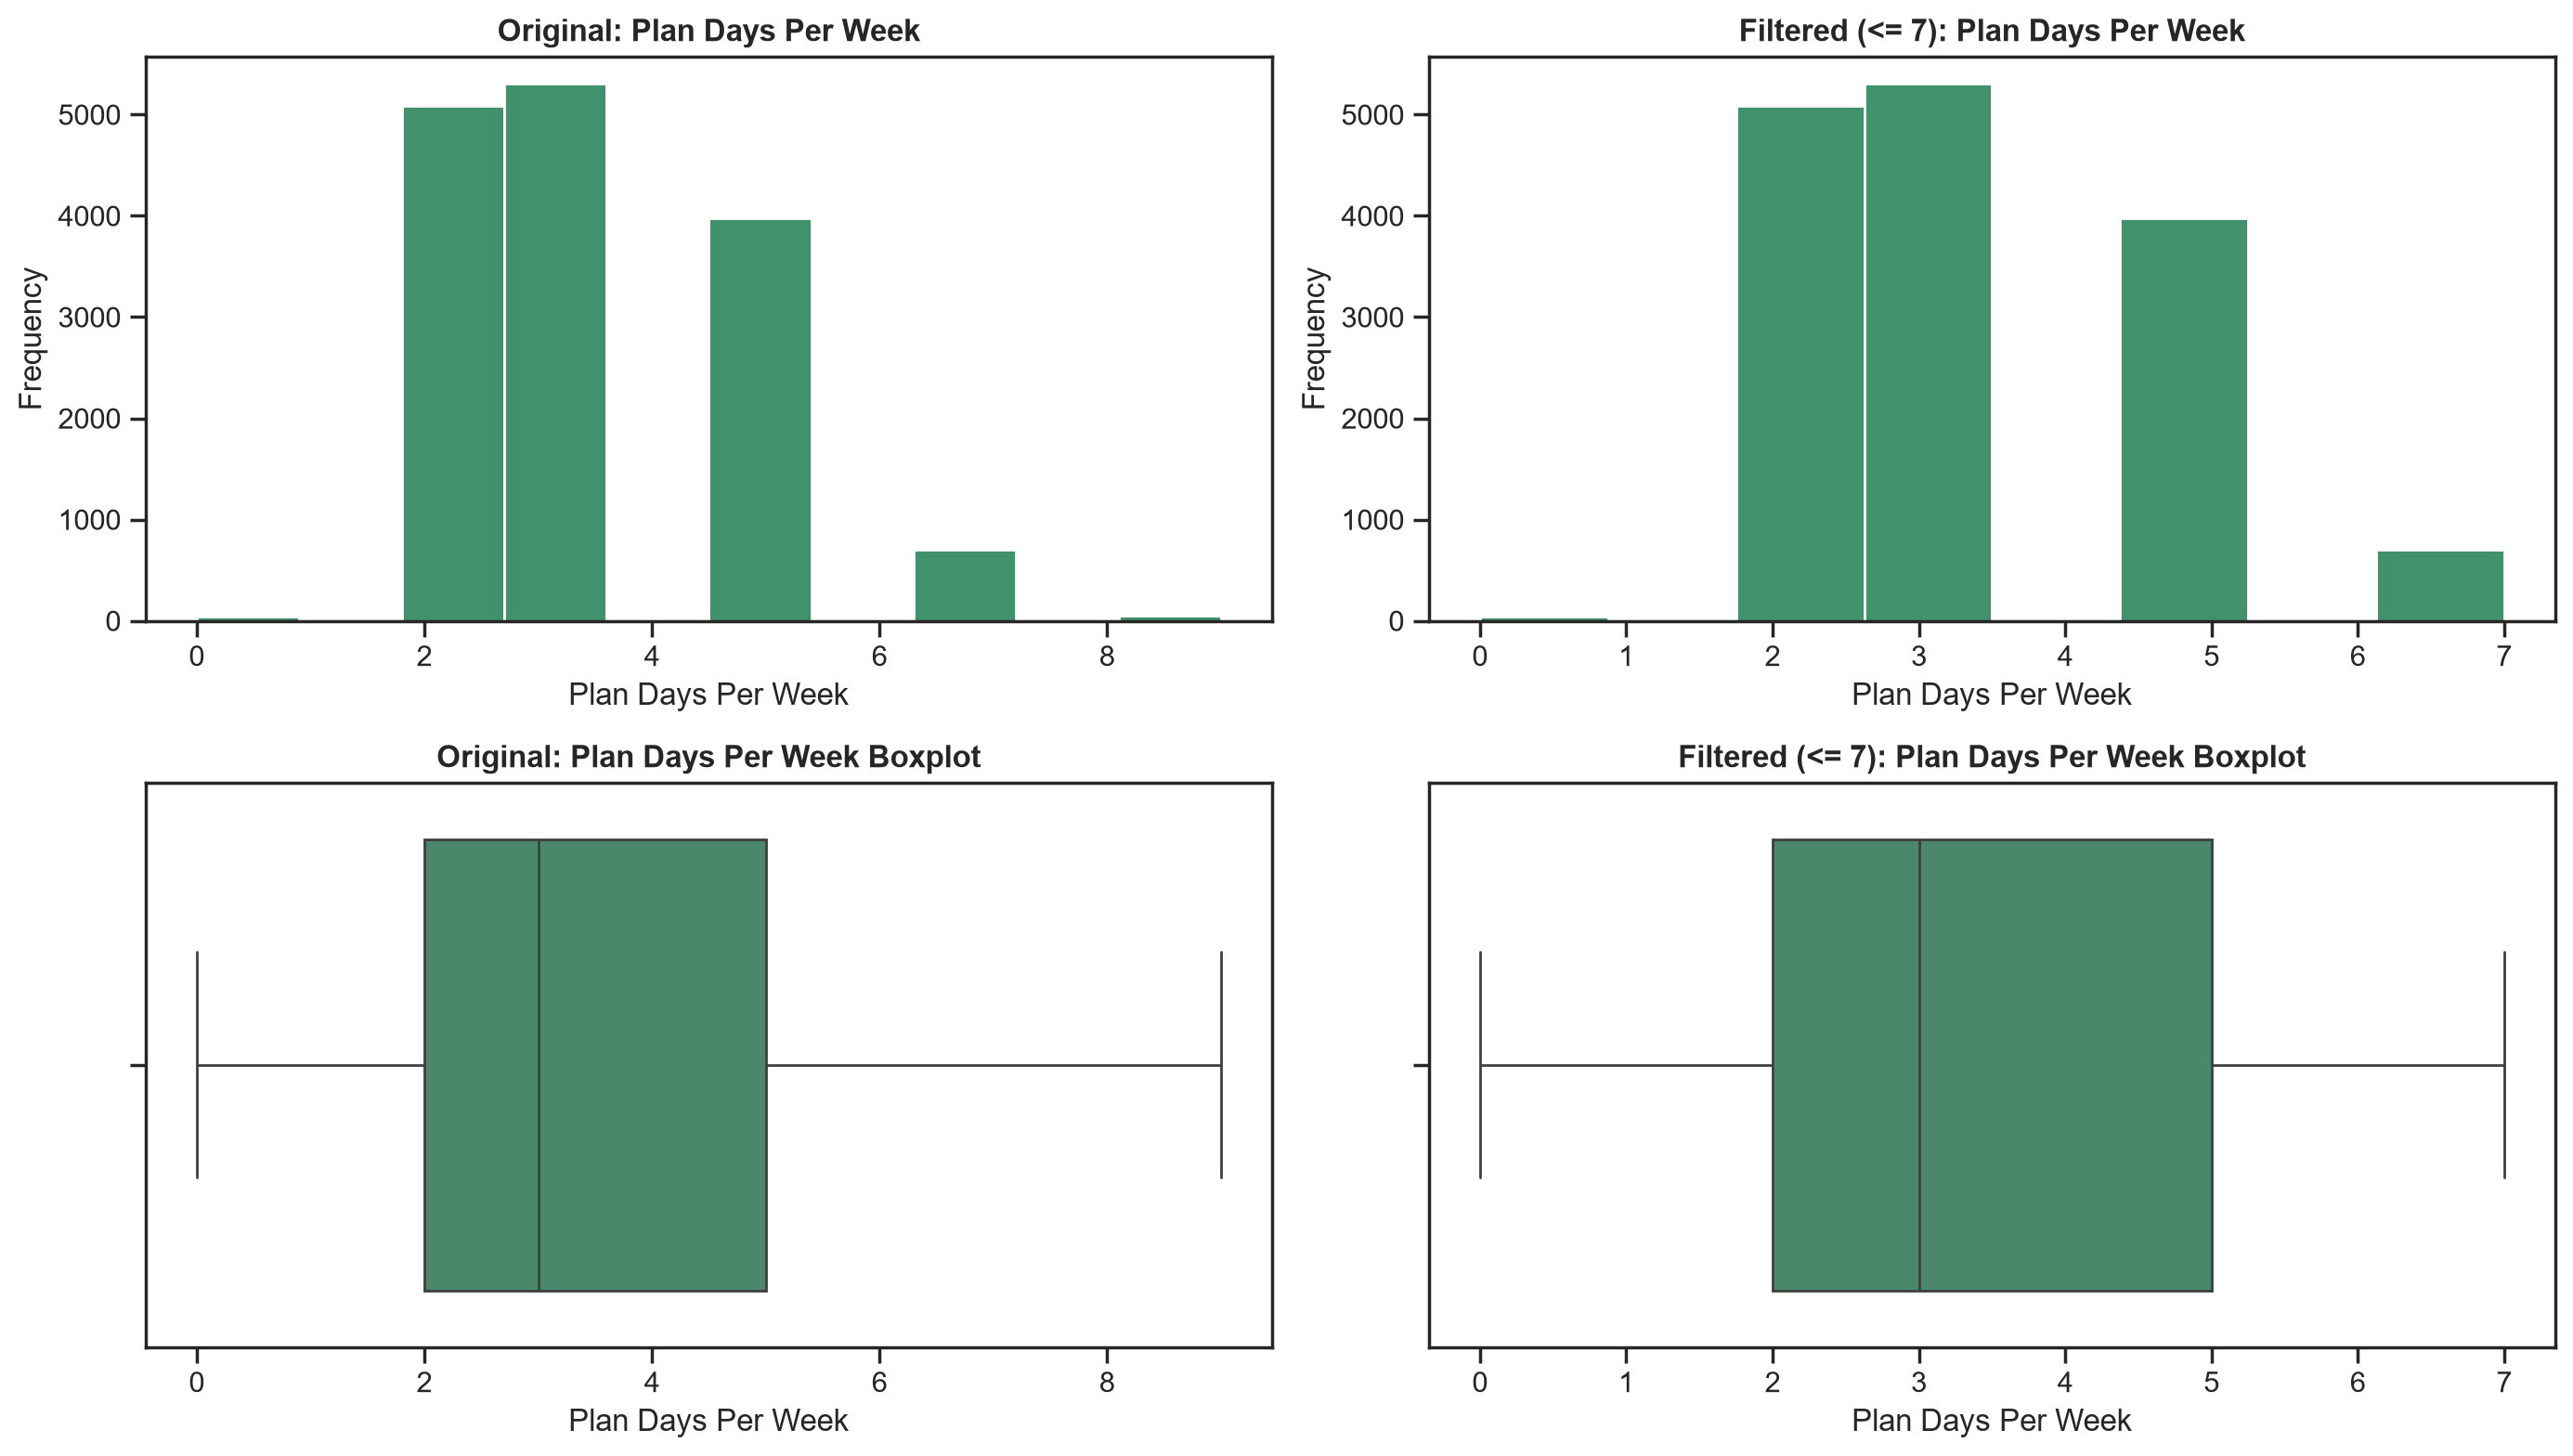

In [24]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, 
        2, 
        figsize=subplot_figsize)

df_plan_clean = df_nodups[df_nodups["plan_days_per_week"] <= 7]

axes[0, 0].hist(df_nodups["plan_days_per_week"].dropna(), bins=10, color=main_color)
axes[0, 1].hist(df_plan_clean["plan_days_per_week"].dropna(), bins=8, color=main_color)

sns.boxplot(x=df_nodups["plan_days_per_week"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_plan_clean["plan_days_per_week"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Plan Days Per Week', fontweight="bold") 
axes[0, 0].set_xlabel('Plan Days Per Week')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (<= 7): Plan Days Per Week', fontweight="bold") 
axes[0, 1].set_xlabel('Plan Days Per Week')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Plan Days Per Week Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Plan Days Per Week')

axes[1, 1].set_title('Filtered (<= 7): Plan Days Per Week Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Plan Days Per Week')

plt.tight_layout()
plt.show()

### 3.1.4. `days_since_last_visit`

For this variable, we filtered out the values that are < 0, since they are impossible.

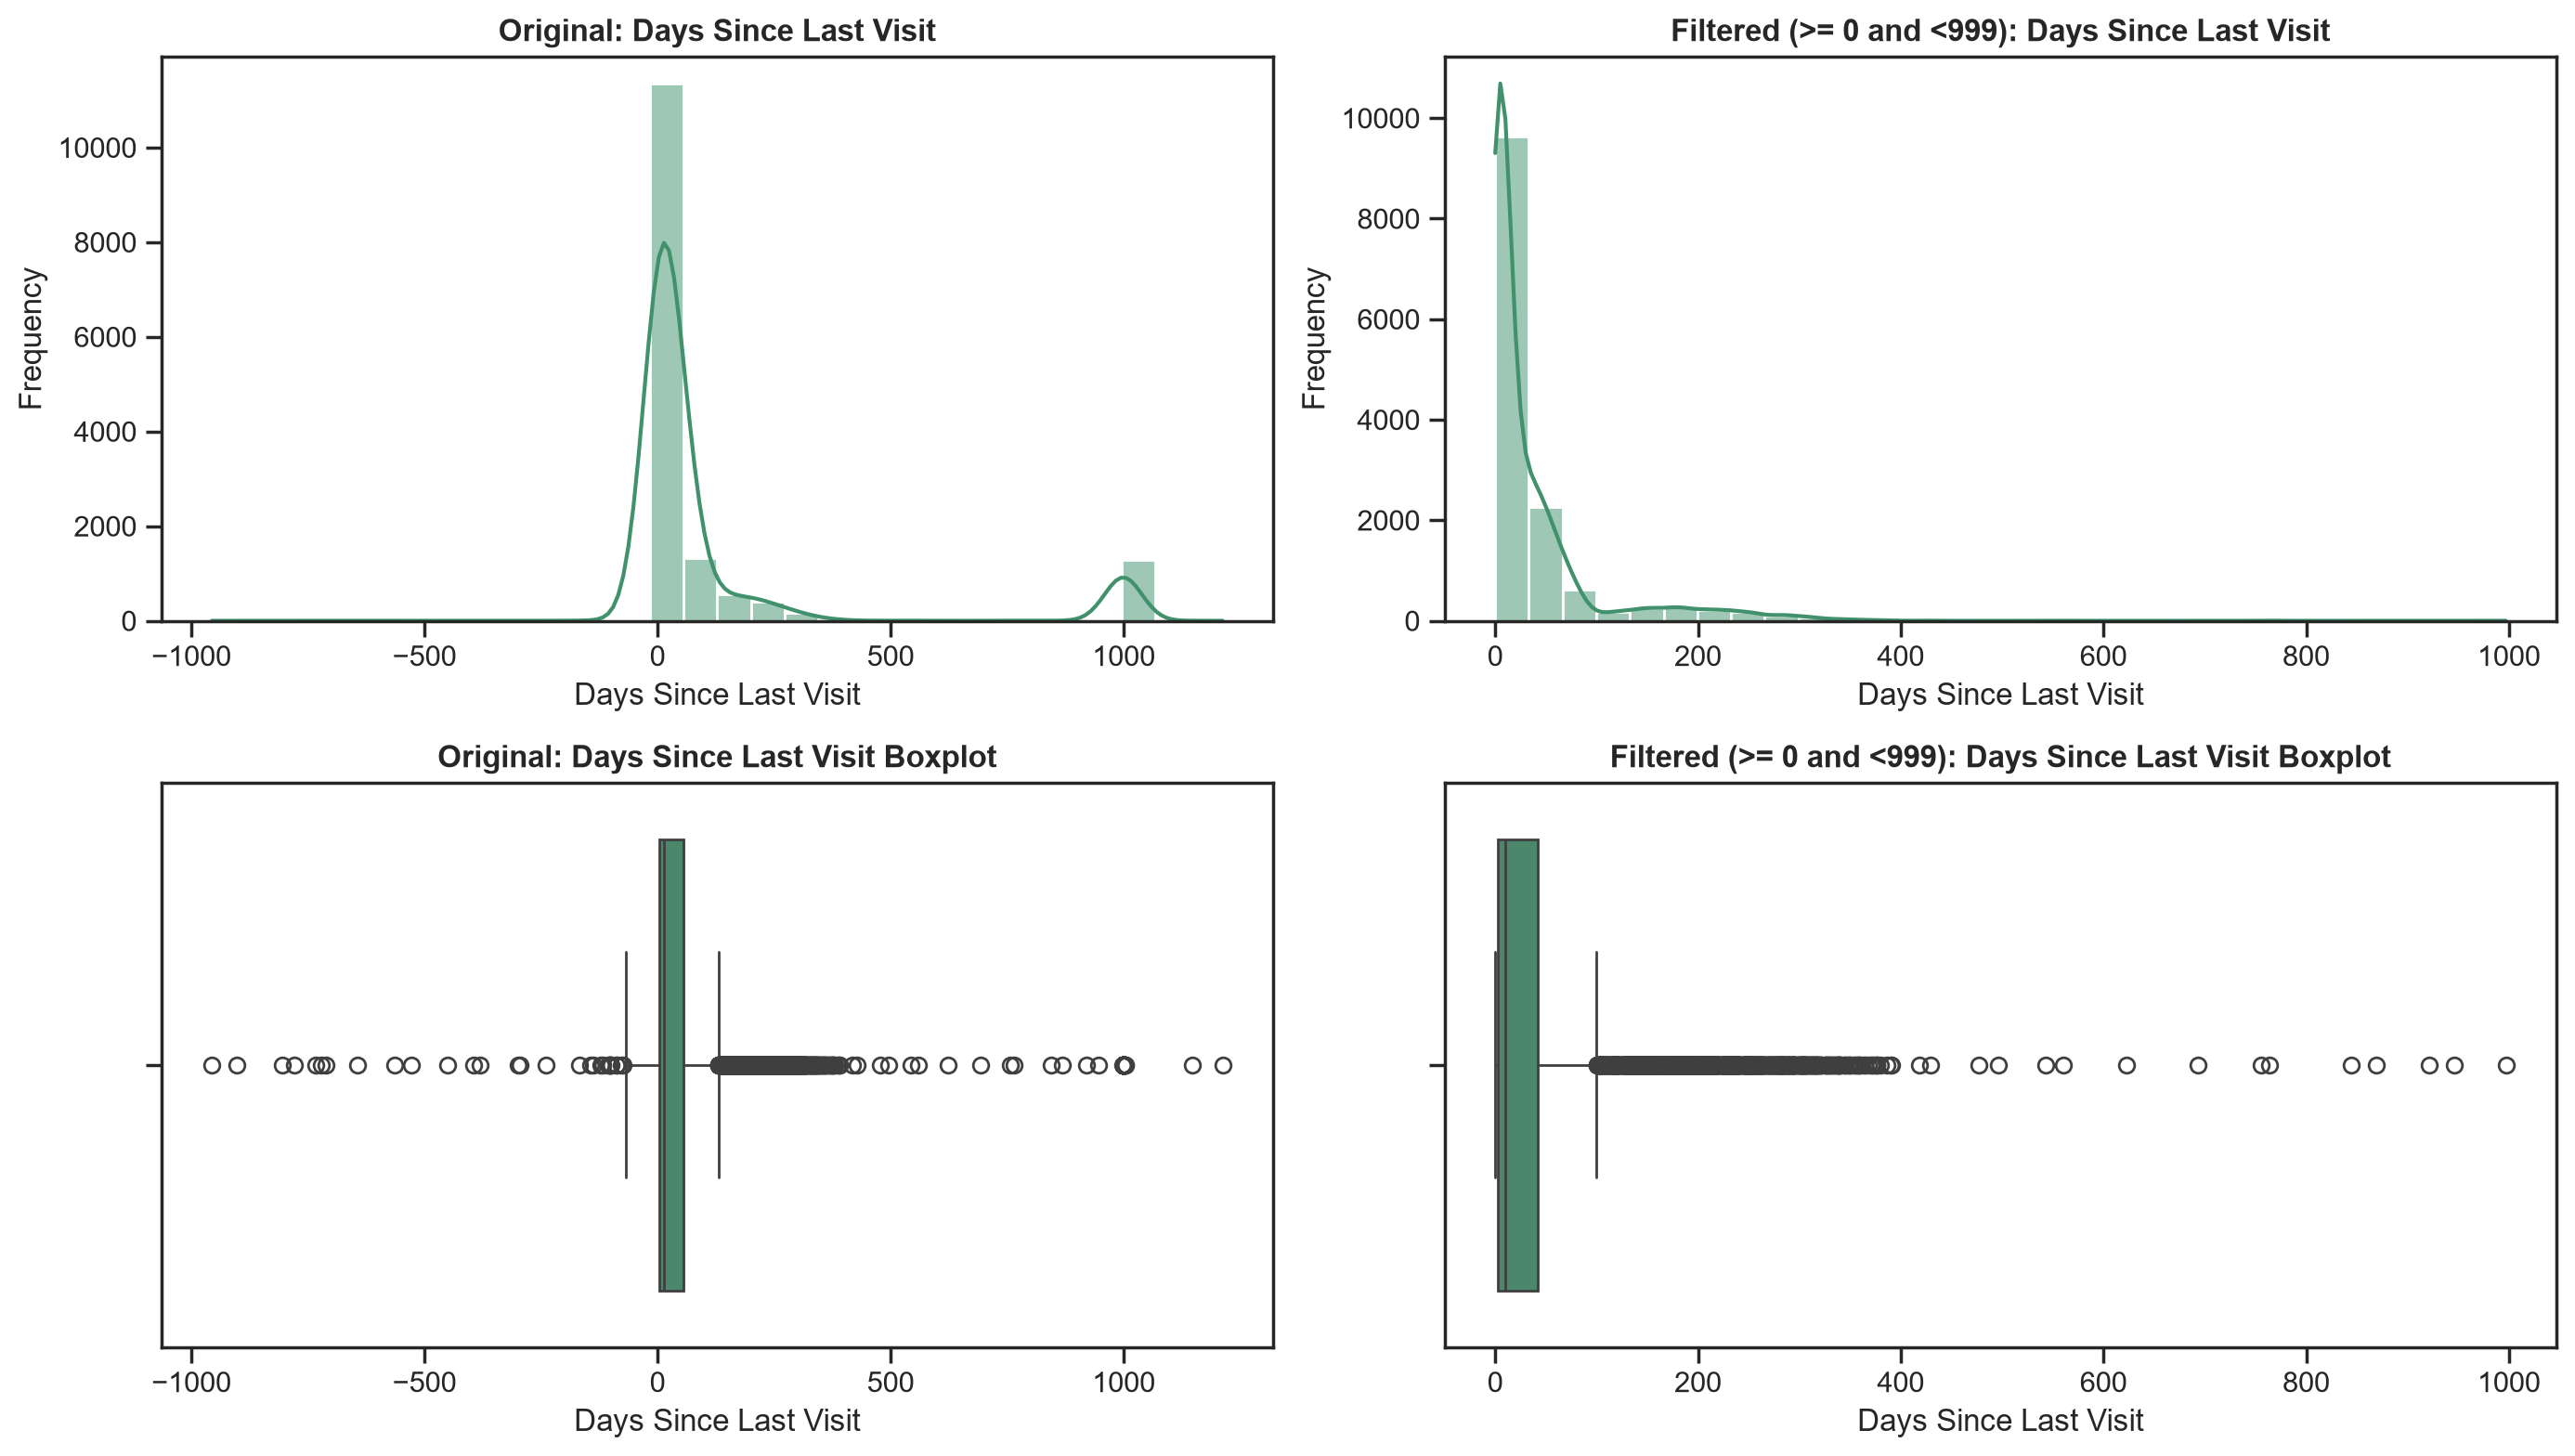

In [25]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_recency_clean = df_nodups[(df_nodups["days_since_last_visit"] >= 0) & (df_nodups["days_since_last_visit"] < 999)]

sns.histplot(df_nodups["days_since_last_visit"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_recency_clean["days_since_last_visit"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["days_since_last_visit"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_recency_clean["days_since_last_visit"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Days Since Last Visit', fontweight="bold")
axes[0, 0].set_xlabel('Days Since Last Visit')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>= 0 and <999): Days Since Last Visit', fontweight="bold")
axes[0, 1].set_xlabel('Days Since Last Visit')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Days Since Last Visit Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Days Since Last Visit')

axes[1, 1].set_title('Filtered (>= 0 and <999): Days Since Last Visit Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Days Since Last Visit')

plt.tight_layout()
plt.show()

In [26]:
(df["days_since_last_visit"]==999).sum()

np.int64(1298)

In [27]:
((df["days_since_last_visit"]==999) & (df["lifetime_value"]==0)).sum()

np.int64(1296)

### 3.1.5. `total_visits` and `avg_weekly_visits`

For this variable, we filtered out the values that are < 0, since they are impossible.

In [28]:
df.shape[0]-((df["total_visits"] >= 0) & (df["total_visits"]<=1000)).sum()

np.int64(49)

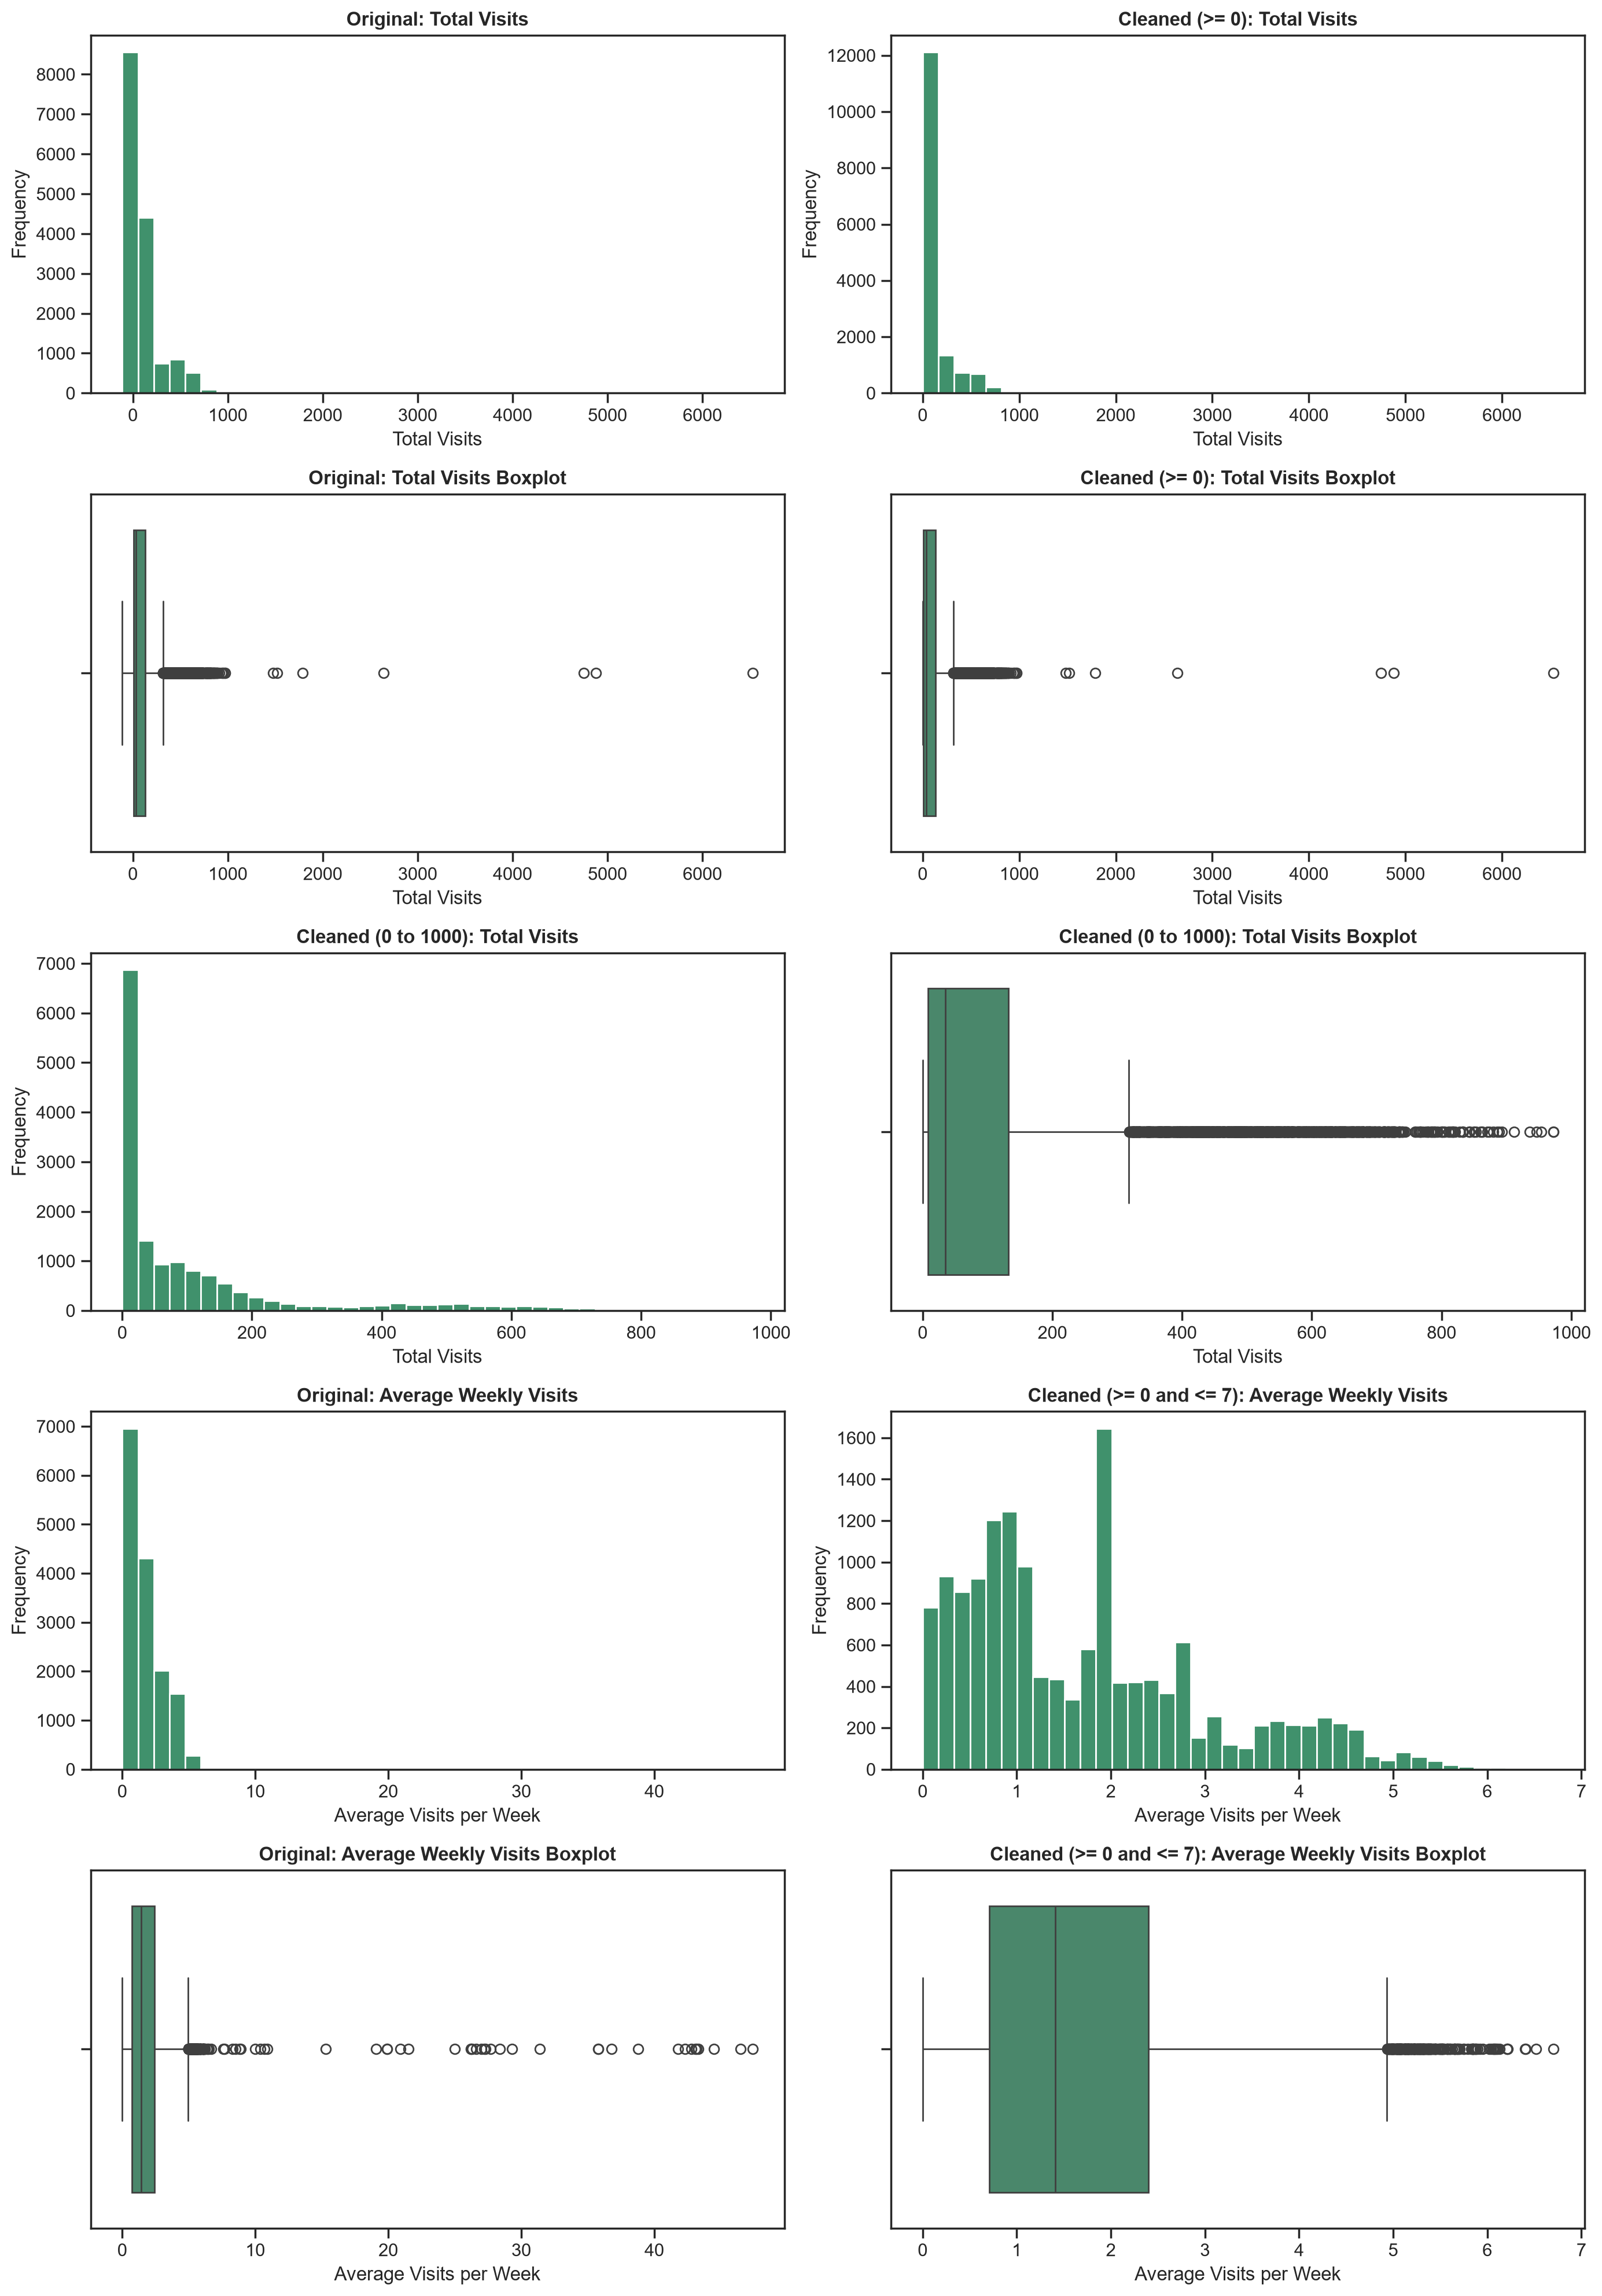

In [29]:
df_visits_clean = df_nodups[df_nodups["total_visits"] >= 0]
df_visits_clean2 = df_nodups[(df_nodups["total_visits"] >= 0) & (df_nodups["total_visits"] <= 1000)]

df_avg_clean = df_nodups[df_nodups["avg_weekly_visits"] >= 0]
df_avg_clean2 = df_nodups[(df_nodups["avg_weekly_visits"] >= 0) & (df_nodups["avg_weekly_visits"] <= 7)]

subplot_figsize = (14, 20)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        5,
        2,
        figsize=subplot_figsize)

# total_visits

axes[0, 0].hist(df_nodups["total_visits"].dropna(), bins=40, color=main_color)
axes[0, 1].hist(df_visits_clean["total_visits"].dropna(), bins=40, color=main_color)

sns.boxplot(x=df_nodups["total_visits"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_visits_clean["total_visits"], color=main_color, ax=axes[1, 1])

# total_visits (intermédio: 0 a 1000)

axes[2, 0].hist(df_visits_clean2["total_visits"].dropna(), bins=40, color=main_color)
sns.boxplot(x=df_visits_clean2["total_visits"], color=main_color, ax=axes[2, 1])

# avg_weekly_visits

axes[3, 0].hist(df_nodups["avg_weekly_visits"].dropna(), bins=40, color=main_color)
axes[3, 1].hist(df_avg_clean2["avg_weekly_visits"].dropna(), bins=40, color=main_color)

sns.boxplot(x=df_nodups["avg_weekly_visits"], color=main_color, ax=axes[4, 0])
sns.boxplot(x=df_avg_clean2["avg_weekly_visits"], color=main_color, ax=axes[4, 1])

# títulos e labels: total_visits

axes[0, 0].set_title('Original: Total Visits', fontweight="bold")
axes[0, 0].set_xlabel('Total Visits')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Cleaned (>= 0): Total Visits', fontweight="bold")
axes[0, 1].set_xlabel('Total Visits')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Total Visits Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Total Visits')

axes[1, 1].set_title('Cleaned (>= 0): Total Visits Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Total Visits')

# títulos e labels: total_visits (0 a 1000)

axes[2, 0].set_title('Cleaned (0 to 1000): Total Visits', fontweight="bold")
axes[2, 0].set_xlabel('Total Visits')
axes[2, 0].set_ylabel('Frequency')

axes[2, 1].set_title('Cleaned (0 to 1000): Total Visits Boxplot', fontweight="bold")
axes[2, 1].set_xlabel('Total Visits')

# títulos e labels: avg_weekly_visits

axes[3, 0].set_title('Original: Average Weekly Visits', fontweight="bold")
axes[3, 0].set_xlabel('Average Visits per Week')
axes[3, 0].set_ylabel('Frequency')

axes[3, 1].set_title('Cleaned (>= 0 and <= 7): Average Weekly Visits', fontweight="bold")
axes[3, 1].set_xlabel('Average Visits per Week')
axes[3, 1].set_ylabel('Frequency')

axes[4, 0].set_title('Original: Average Weekly Visits Boxplot', fontweight="bold")
axes[4, 0].set_xlabel('Average Visits per Week')

axes[4, 1].set_title('Cleaned (>= 0 and <= 7): Average Weekly Visits Boxplot', fontweight="bold")
axes[4, 1].set_xlabel('Average Visits per Week')

plt.tight_layout()
plt.show()

### 3.1.6. `entitled_visits_last_period` and `actual_visits_last_period`

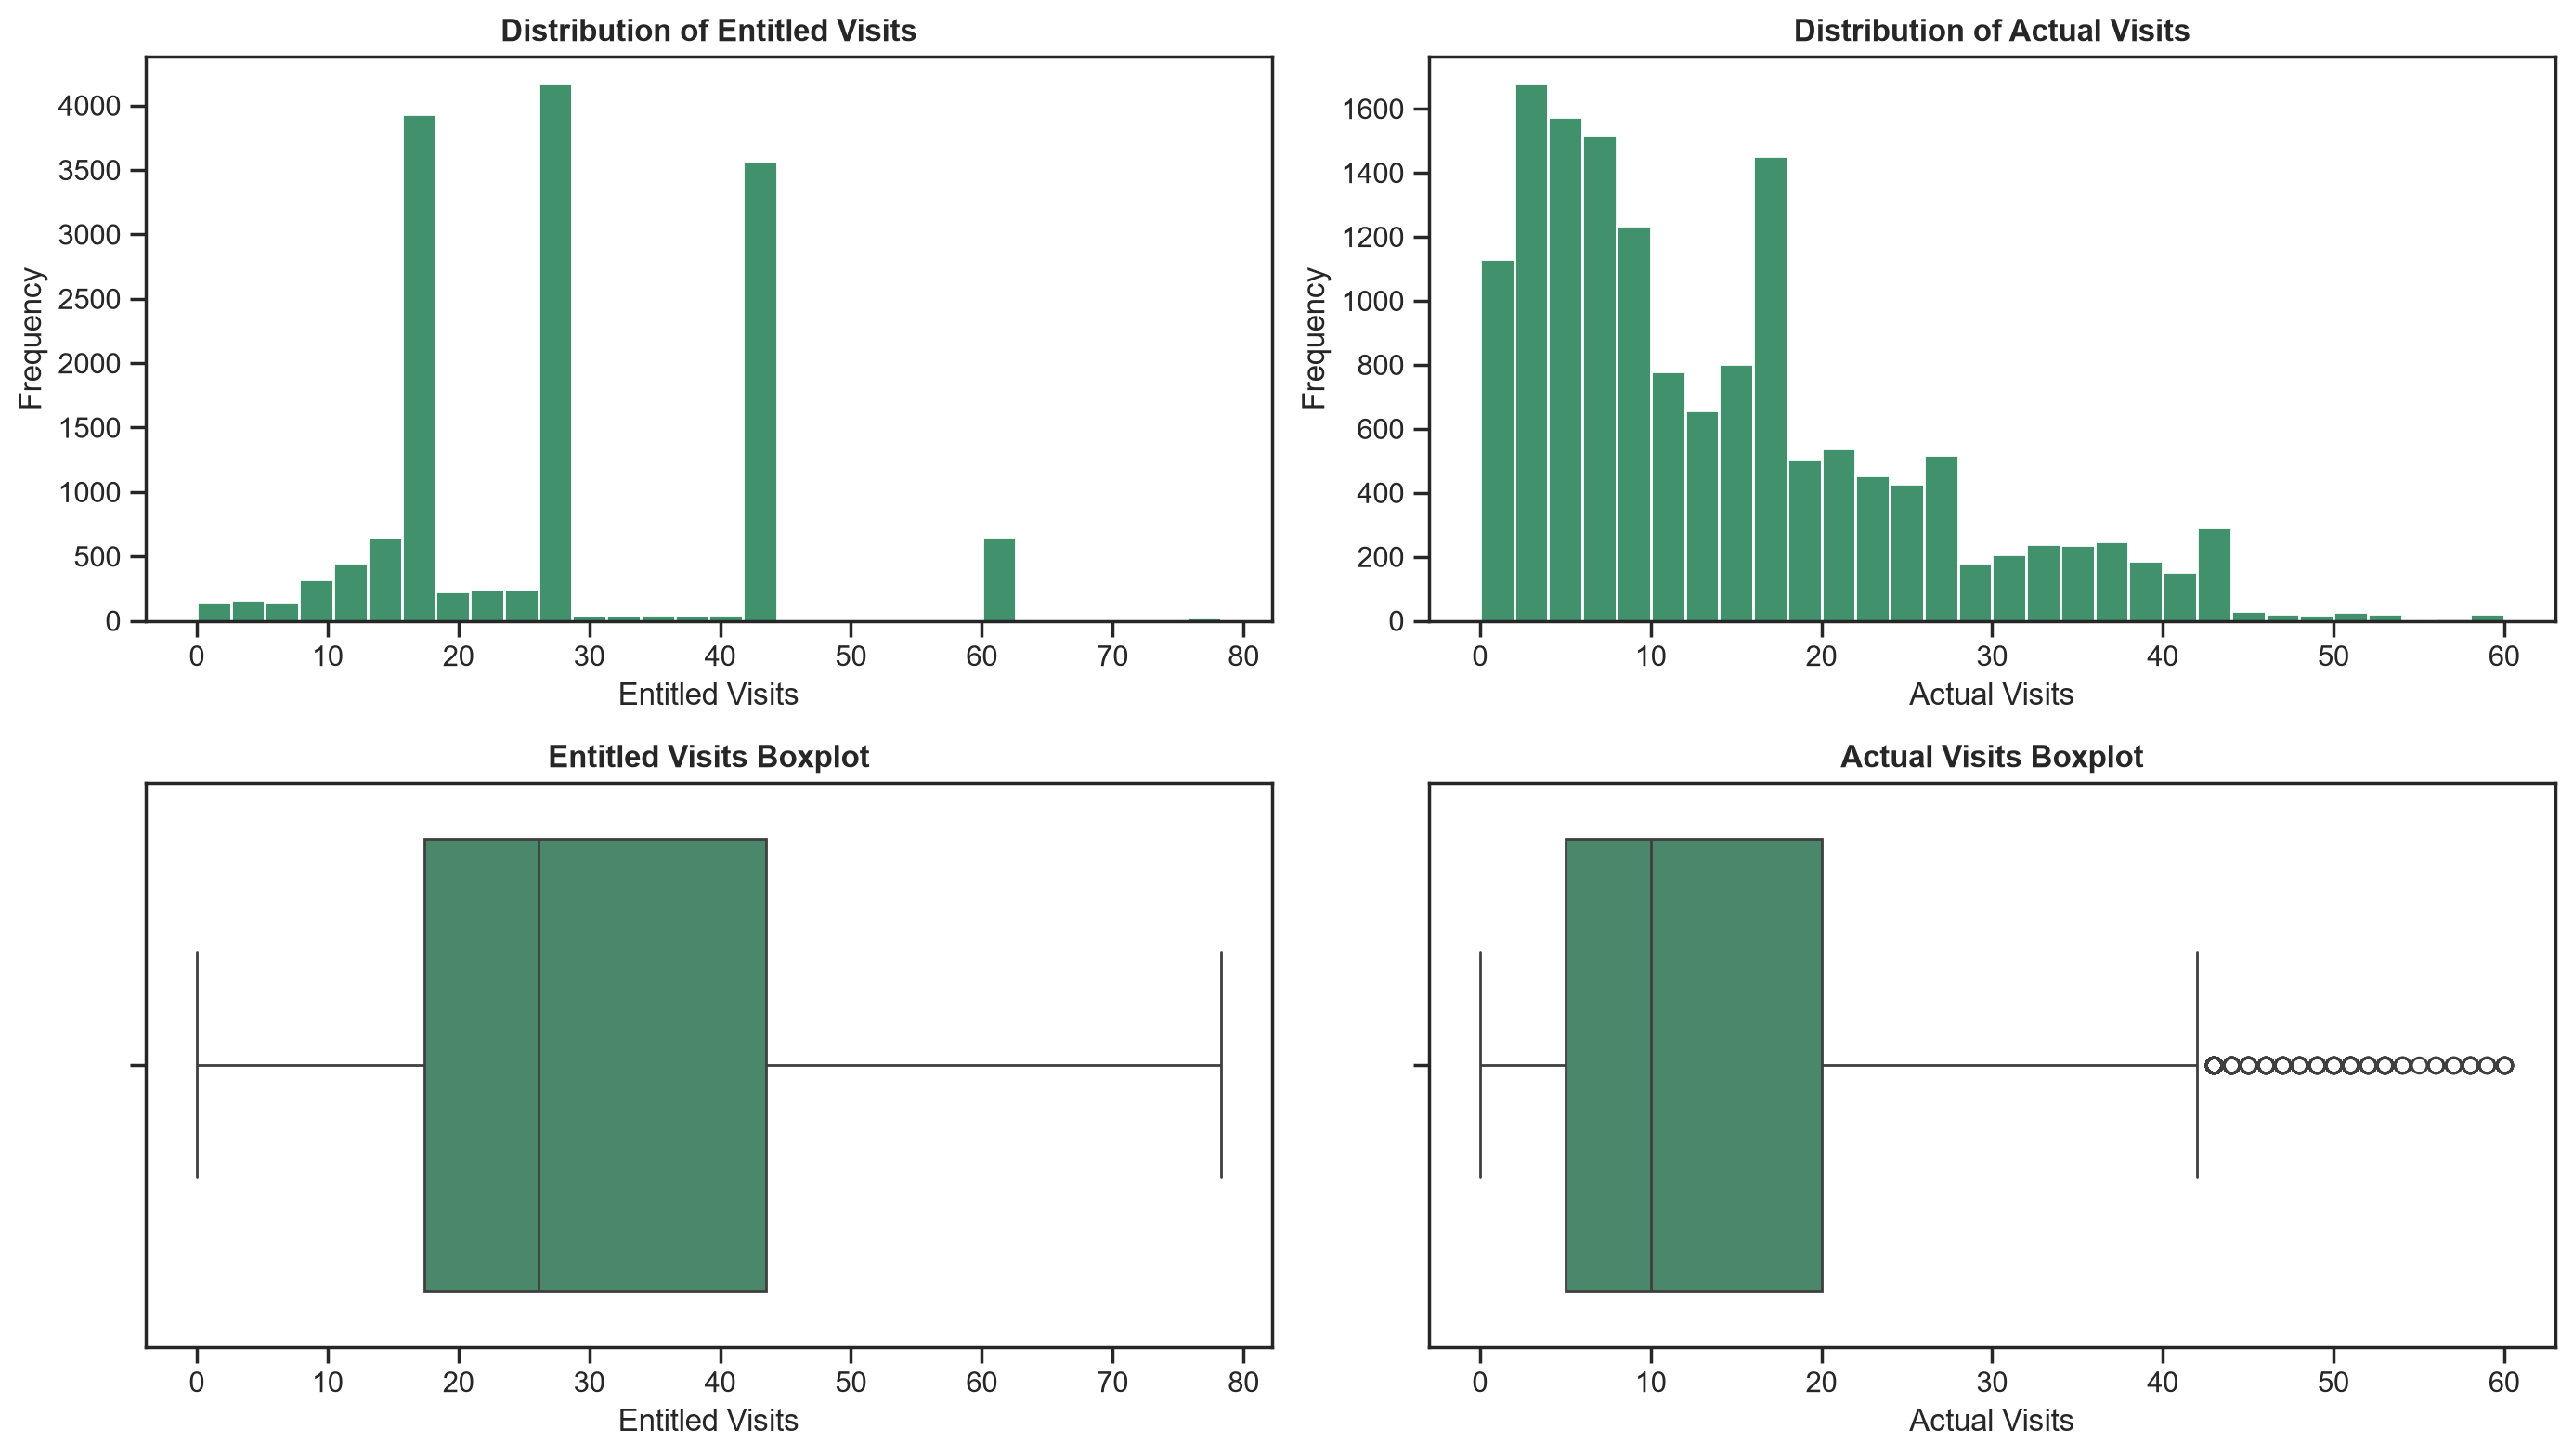

In [30]:
subplot_figsize = (14, 8) 

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

axes[0, 0].hist(df_nodups["entitled_visits_last_period"].dropna(), bins=30, color=main_color)
axes[0, 1].hist(df_nodups["actual_visits_last_period"].dropna(), bins=30, color=main_color)

sns.boxplot(x=df_nodups["entitled_visits_last_period"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_nodups["actual_visits_last_period"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Distribution of Entitled Visits', fontweight="bold") 
axes[0, 0].set_xlabel('Entitled Visits')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Distribution of Actual Visits', fontweight="bold") 
axes[0, 1].set_xlabel('Actual Visits')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Entitled Visits Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Entitled Visits')

axes[1, 1].set_title('Actual Visits Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Actual Visits')

plt.tight_layout()
plt.show()

The distribution of **entitled visits** is concentrated around a few specific values (about 17, 26, 43 and 60), which is expected if it is a theoretical value defined by the company according to the characteristics of each plan. In contrast, **actual visits** are right-skewed, with most customers having few visits, and the boxplot shows outliers above about 42 visits.

Comparing the two, the median of actual visits (about 10) is well below the median of entitled visits (about 26), and the maximum of actual visits (about 60) is also below the maximum of entitled visits (about 76). This *suggests* that customers use only part of their entitlement, although no firm conclusion can be drawn at this stage. This relationship is analysed in more detail later, through a usage rate variable.

### 3.1.7. `meeting_room_hours` and `event_space_hours`

For both variables, we filtered out the values that are < 0, since they are impossible.

In [31]:
cols = ["meeting_room_hours", "event_space_hours"]

rows = {}
for c in cols:
    s = df_nodups[c].dropna()
    pos = s[s > 0]
    rows[c] = {"% zeros": (s == 0).mean() * 100, "n negative": (s < 0).sum(), "n positive": len(pos),
               "median (positive)": pos.median(), "p90": pos.quantile(0.90),
               "p99": pos.quantile(0.99), "max": pos.max()}

pd.DataFrame(rows).T.round(1)

,% zeros,n negative,n positive,median (positive),p90,p99,max
meeting_room_hours,65.2,16.0,4822.0,32.7,182.6,508.2,41220.0
event_space_hours,88.5,8.0,1741.0,23.3,115.4,318.9,602.8


Without a logarithmic scale, the original distributions of both variables could not be visualised, as a few extreme values stretch the axis and hide the rest of the data. Before drawing any conclusion, it is important to note that most customers **do not** use these services: 65.2% of the records have zero `meeting_room_hours` and 88.5% have zero `event_space_hours`. The plots below therefore show only the positive values (a small number of negative values, 16 and 8 respectively, were excluded as invalid), and all the statistics refer to customers who actually use the service.


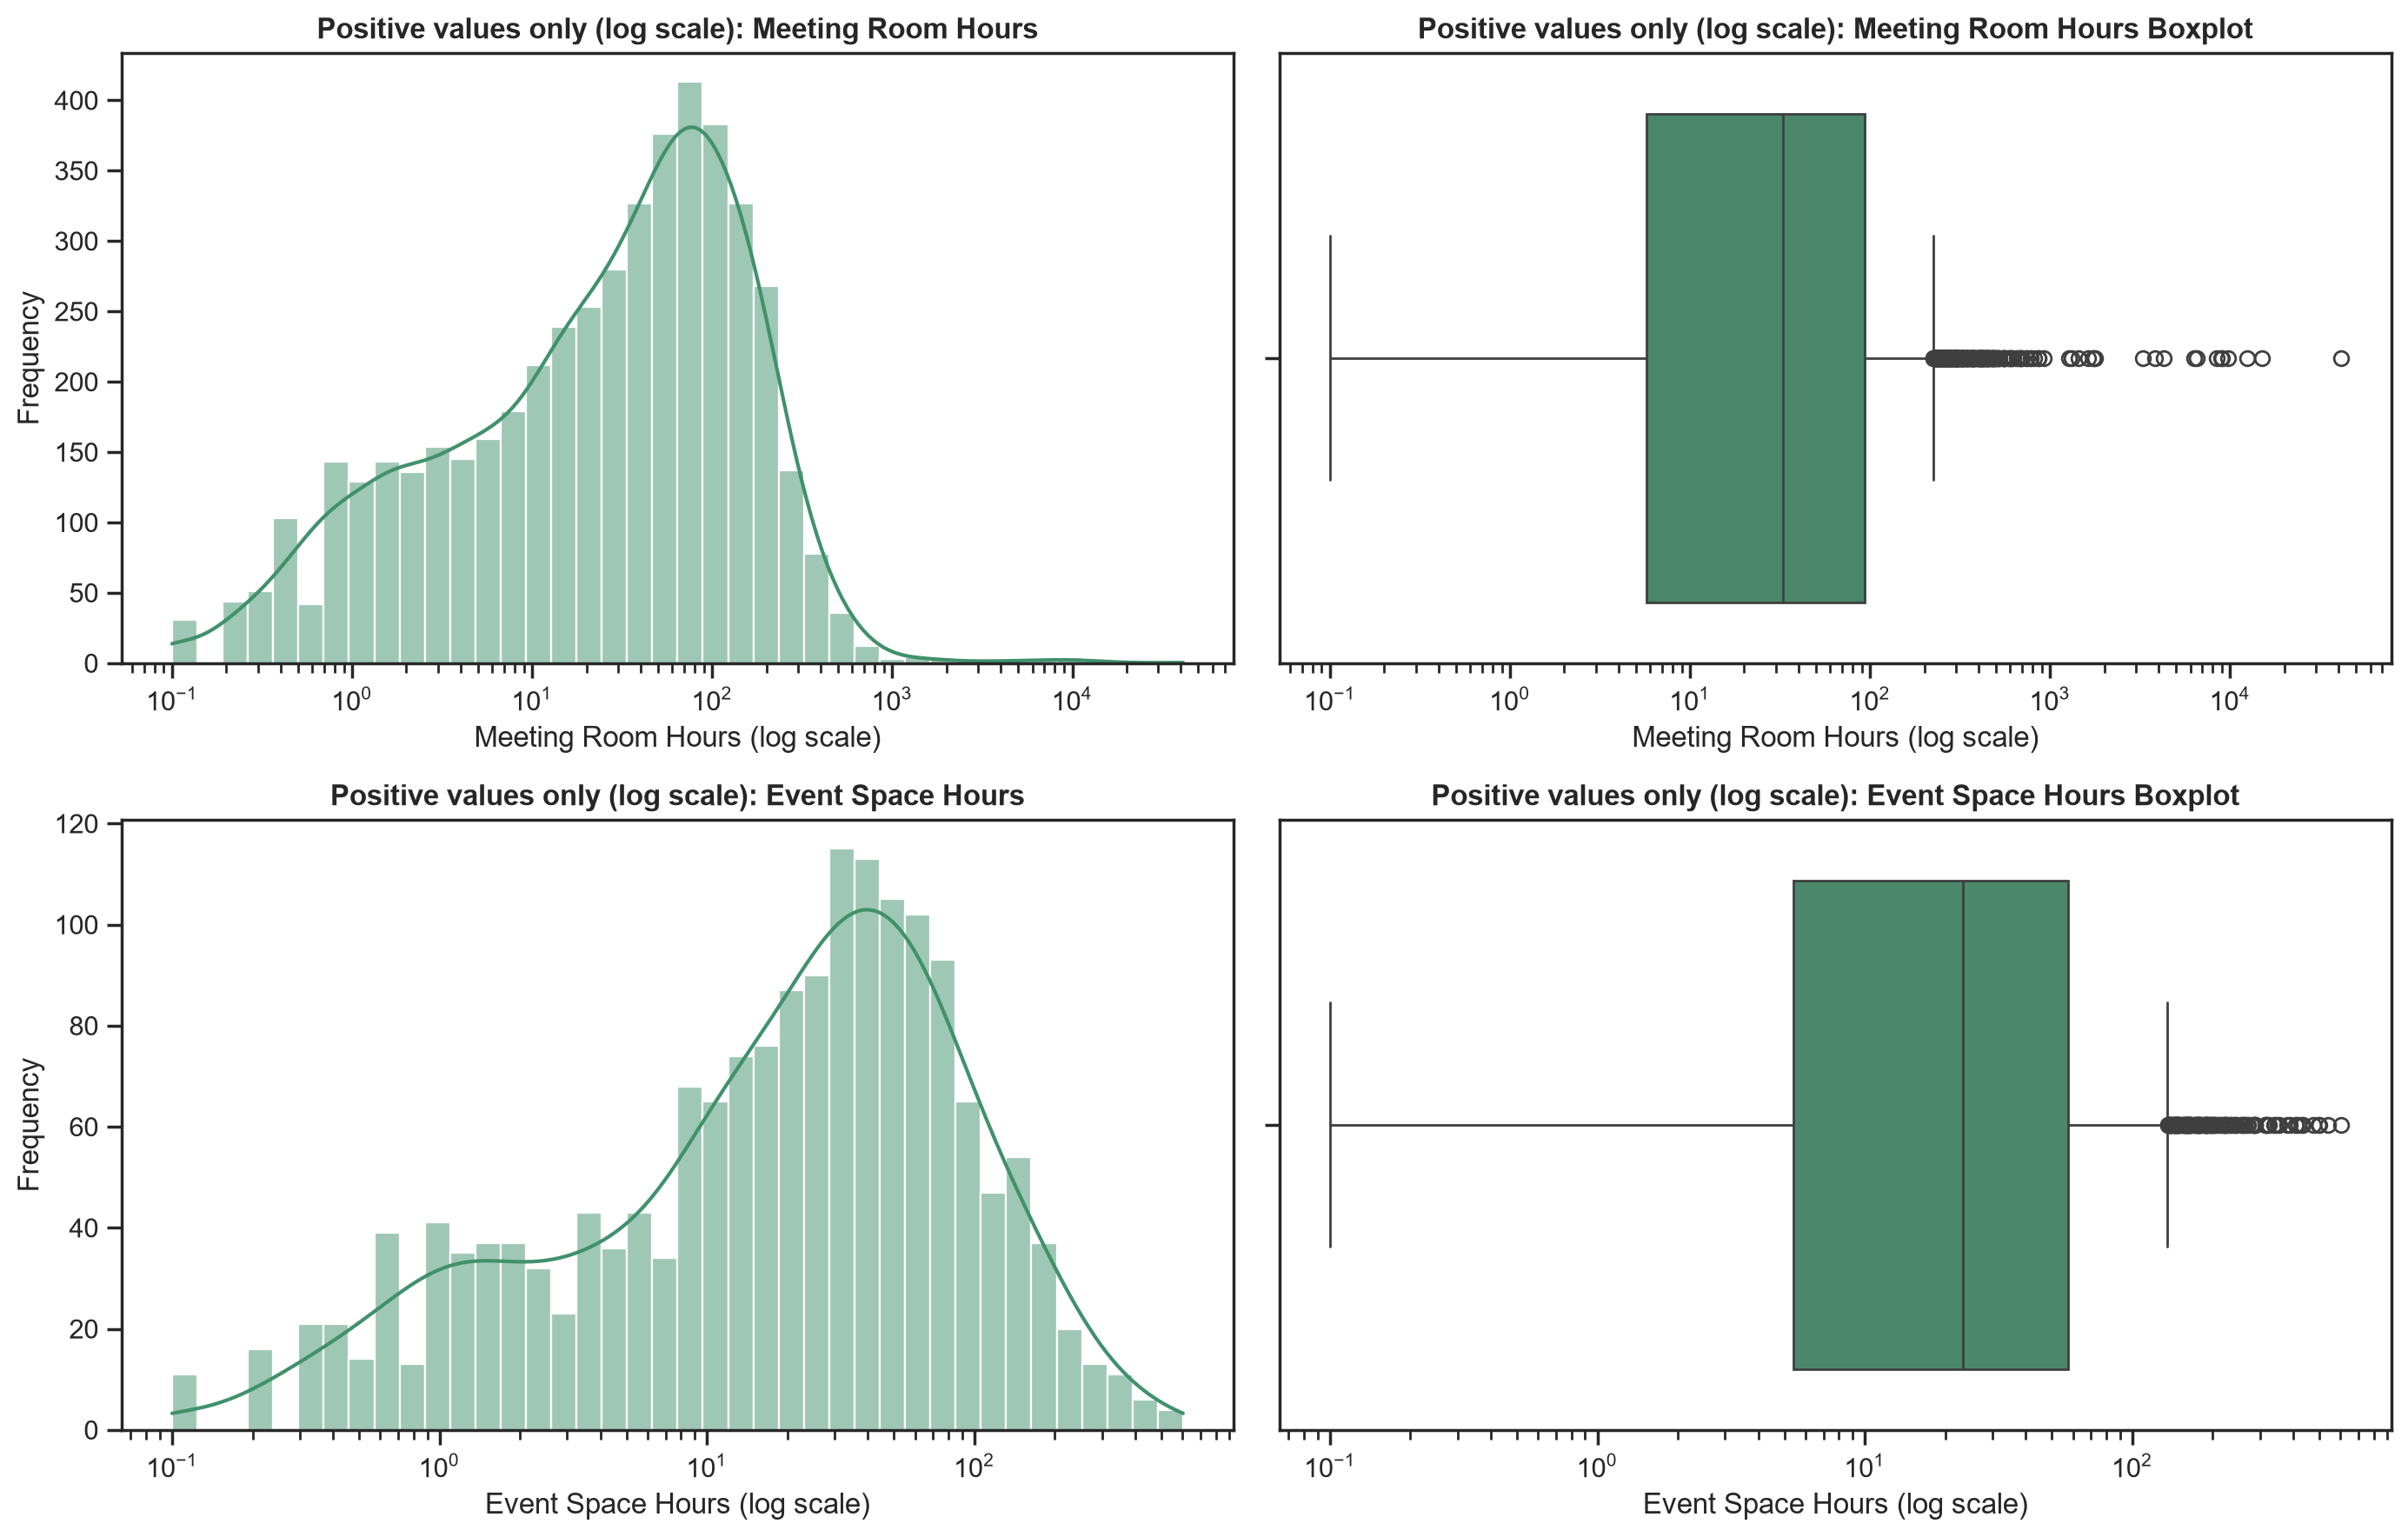

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, (c, name) in enumerate([("meeting_room_hours", "Meeting Room Hours"),
                               ("event_space_hours", "Event Space Hours")]):
    pos = df_nodups.loc[df_nodups[c] > 0, c]

    sns.histplot(pos, bins=40, log_scale=True, color=main_color, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Positive values only (log scale): {name}', fontweight="bold")
    axes[i, 0].set_xlabel(name + ' (log scale)')
    axes[i, 0].set_ylabel('Frequency')

    sns.boxplot(x=pos, color=main_color, ax=axes[i, 1])
    axes[i, 1].set_xscale("log")
    axes[i, 1].set_title(f'Positive values only (log scale): {name} Boxplot', fontweight="bold")
    axes[i, 1].set_xlabel(name + ' (log scale)')

plt.tight_layout()
plt.show()

For **meeting room hours**, the positive values are concentrated, on the log scale, between about 10⁰ and 10³ hours, with a peak at around 80 hours and a median of about 33 hours. For **event space hours**, the pattern is similar but shifted to lower values, with a peak at around 40 hours and a median of about 23 hours. The frequencies are lower because far fewer customers use the event space (about 1700, against about 4800 for meeting rooms; see the table above the plots).

Both variables have many points flagged as outliers by the boxplot rule. The boxplot whiskers are computed on the original values (the log scale is only used to display them), so these points should be read as customers with very intensive use (for example, members who rely on the coworking space mainly for meetings or events) and not necessarily as errors. The exception are the few values of thousands of hours in `meeting_room_hours` (up to about 41000, which would correspond to years of continuous use), which are very likely data errors, although they could also reflect team accounts or a unit problem.

### 3.1.8. `guest_passes_issued`

In [33]:
raw = df_nodups["guest_passes_issued"]
s = raw.dropna()
pos = s[s > 0]

pd.DataFrame({"n missing": [raw.isna().sum()],
              "% missing": [raw.isna().mean() * 100],
              "% zeros": [(s == 0).mean() * 100],
              "n negative": [(s < 0).sum()],
              "n positive": [len(pos)],
              "median (positive)": [pos.median()],
              "p90": [pos.quantile(0.90)],
              "p99": [pos.quantile(0.99)],
              "max": [pos.max()]},
             index=["guest_passes_issued"]).round(1)

,n missing,% missing,% zeros,n negative,n positive,median (positive),p90,p99,max
guest_passes_issued,1248,8.2,82.4,7,2438,20.0,89.3,219.0,589.0


`guest_passes_issued` has the same structure as the previous service variables: it is zero-inflated, with 82.4% of the non-missing records equal to zero, which means that most customers do not issue guest passes. In addition, there are negative, which is invalid and was excluded from the plot. Only 2438 customers have a positive value, so the plot below shows only these customers, on a logarithmic scale one more time.

Among them, the distribution is strongly right-skewed: the median is 20 passes, 90% of the customers issued fewer than about 89 and only 1% more than about 219. The maximum (589) is only about 2.7 times the 99th percentile, in contrast with `meeting_room_hours`, so there is no evidence of implausible values here and the extreme points are consistent with customers who regularly host guests. As the variable is a count, the histogram may show gaps at low values, which is expected.

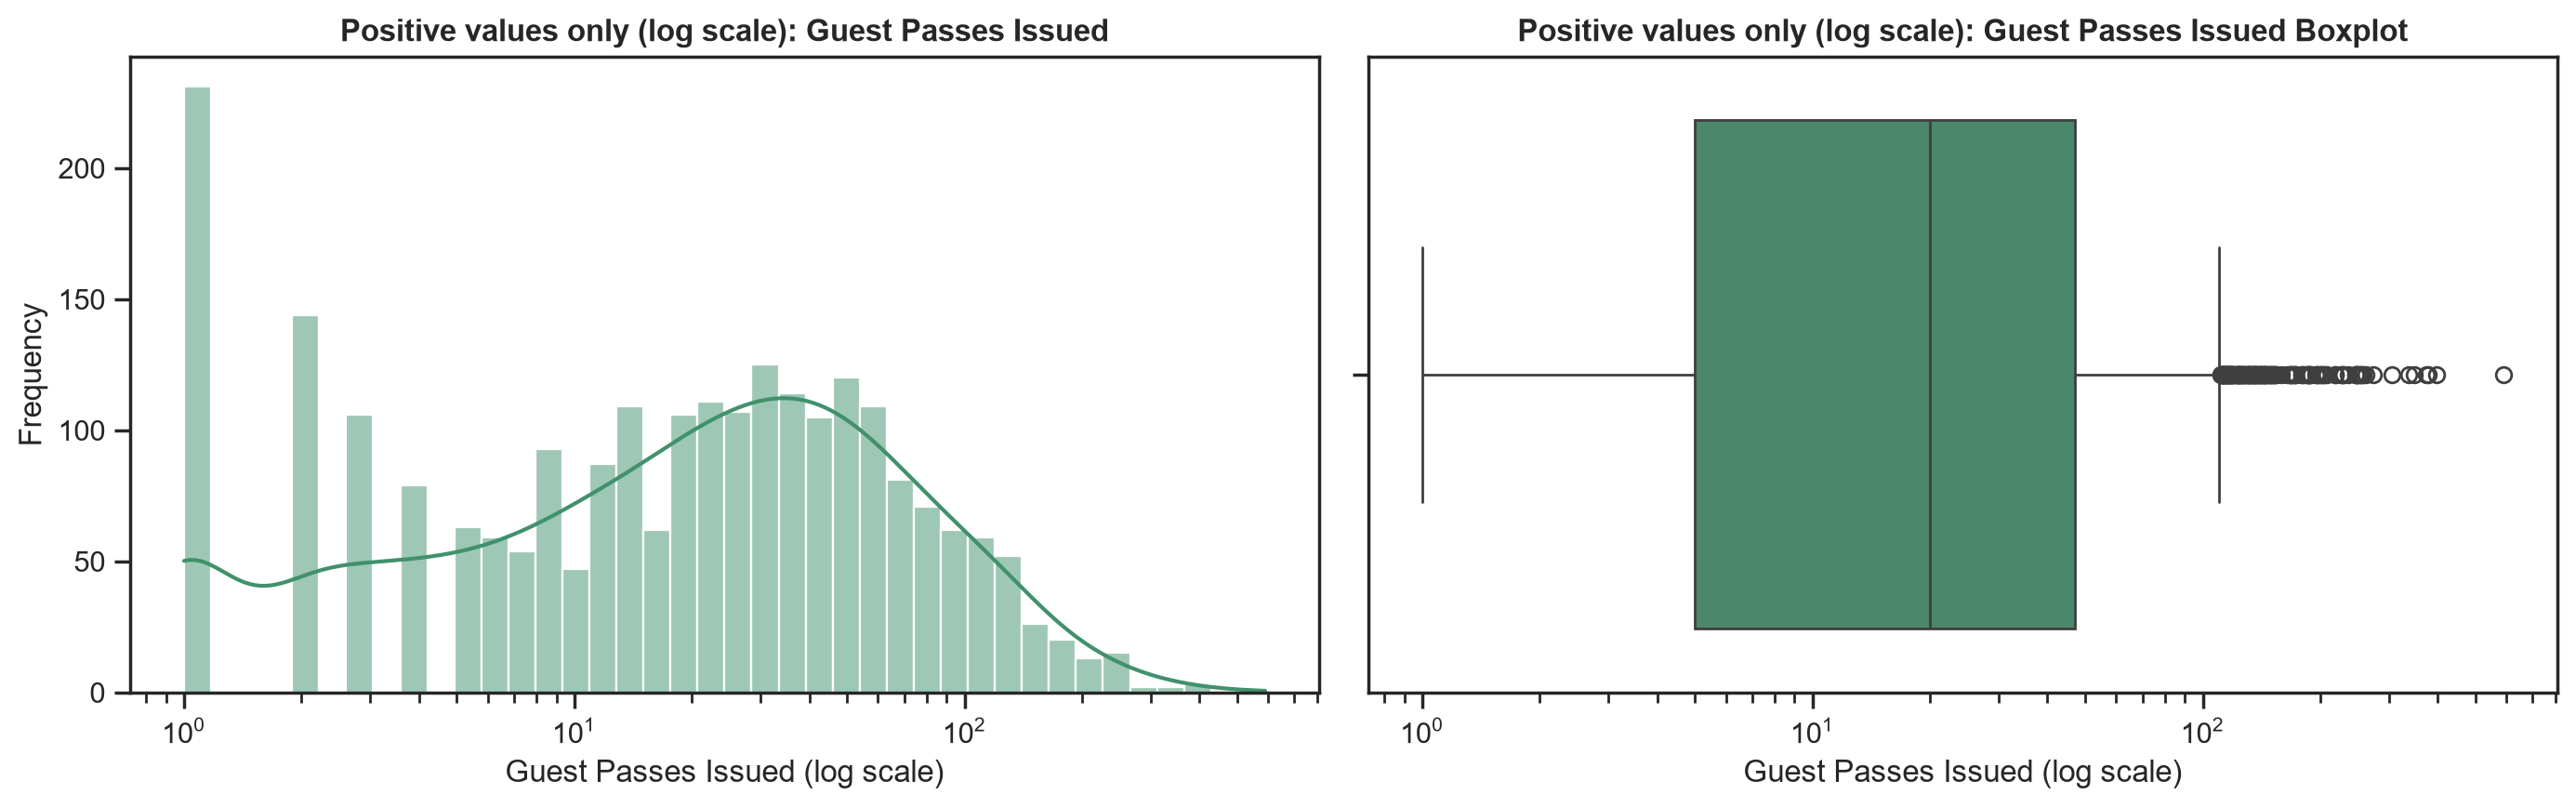

In [34]:
pos = df_nodups.loc[df_nodups["guest_passes_issued"] > 0, "guest_passes_issued"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(pos, bins=40, log_scale=True, color=main_color, kde=True, ax=axes[0])
axes[0].set_title('Positive values only (log scale): Guest Passes Issued', fontweight="bold")
axes[0].set_xlabel('Guest Passes Issued (log scale)')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=pos, color=main_color, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title('Positive values only (log scale): Guest Passes Issued Boxplot', fontweight="bold")
axes[1].set_xlabel('Guest Passes Issued (log scale)')

plt.tight_layout()
plt.show()

Among customers who issue guest passes, the most common number is 1, followed by 2, 3 and 4, but most customers issue many more: the typical (median) customer issues 20 passes, and half of them issue between about 5 and 48. The separate bars at low values simply reflect that passes are counted in whole numbers, and do not mean there is a different group of customers.

Beyond that, the number of passes varies a lot from customer to customer, with most customers concentrated around 35 passes. The boxplot also shows some customers who issue far more than the rest (above about 110 passes, up to 589). These are probably customers who regularly host guests, and not necessarily errors.

### 3.1.9. `n_renewals`

For this variable we filtered out the values that are < 0, since they are impossible.

In [38]:
raw = df_nodups["n_renewals"]
s = raw.dropna()
pos = s[s > 0]

pd.DataFrame({"n missing": [raw.isna().sum()],
              "% missing": [raw.isna().mean() * 100],
              "% zeros": [(s == 0).mean() * 100],
              "n negative": [(s < 0).sum()],
              "n positive": [len(pos)],
              "median (positive)": [pos.median()],
              "p90": [pos.quantile(0.90)],
              "p99": [pos.quantile(0.99)],
              "max": [pos.max()]},
             index=["guest_passes_issued"]).round(1)

,n missing,% missing,% zeros,n negative,n positive,median (positive),p90,p99,max
guest_passes_issued,0,0.0,50.1,65,7500,2.0,4.0,6.0,6


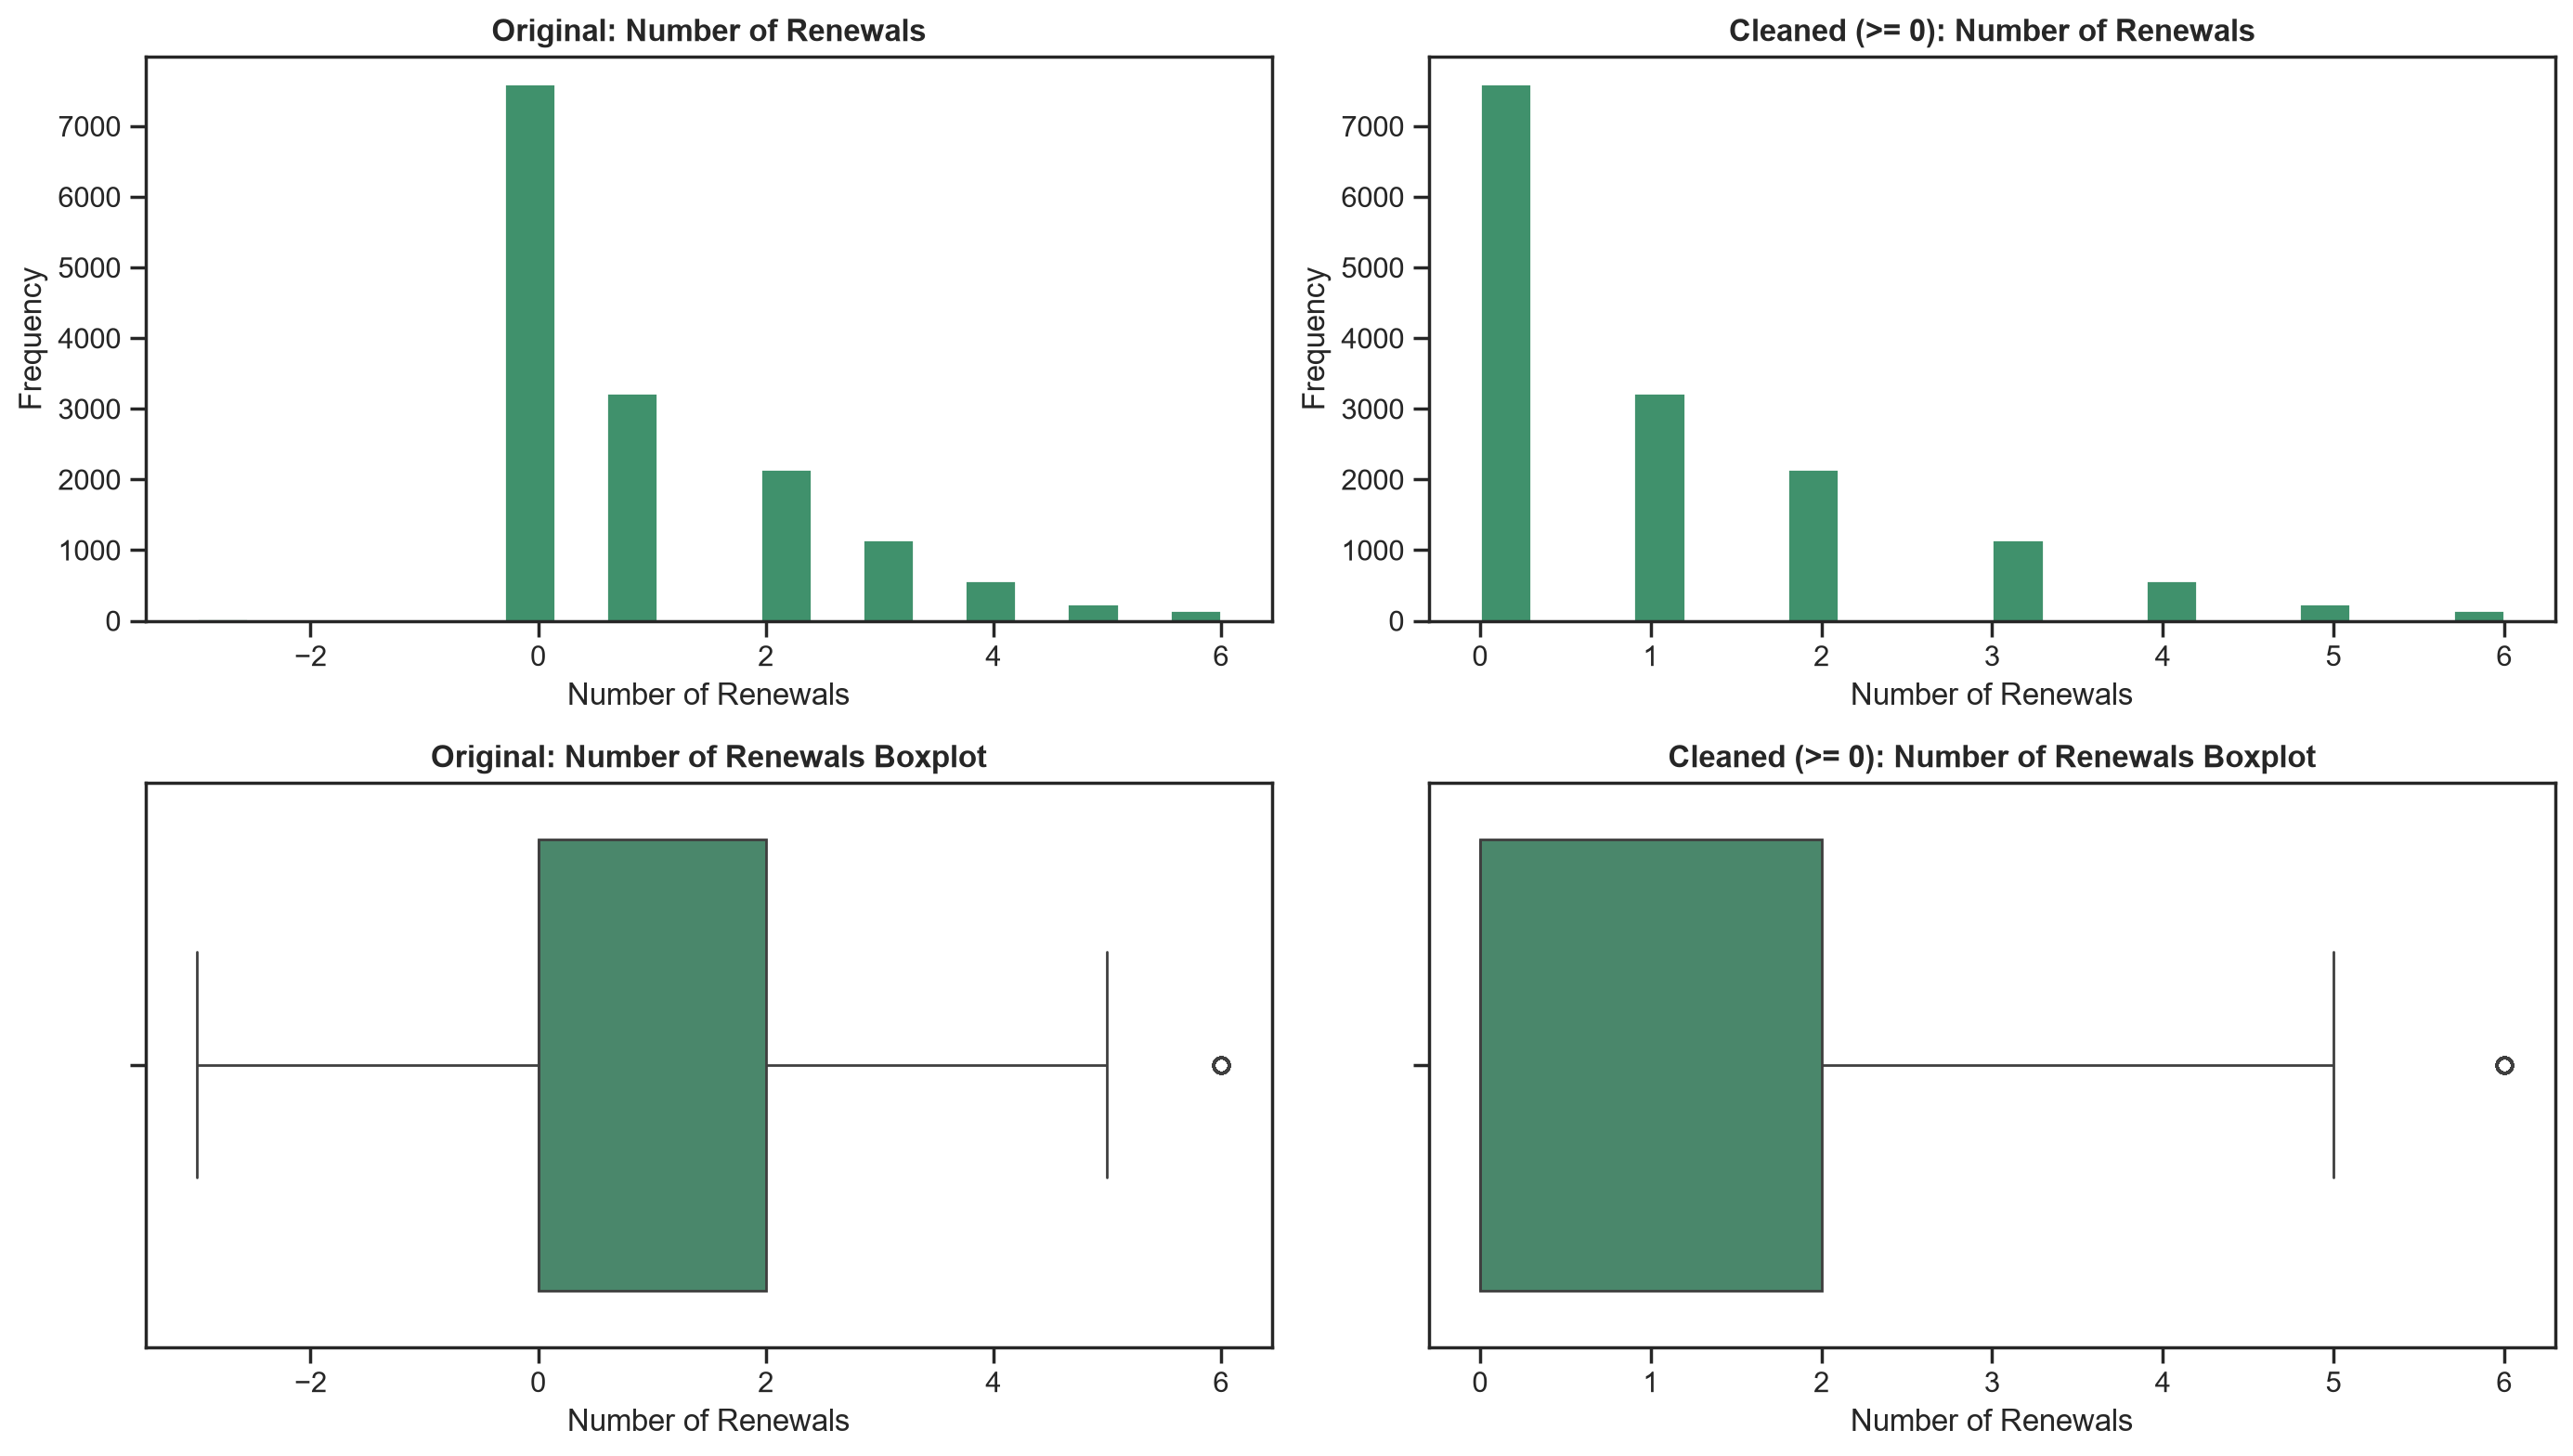

In [35]:
df_renewals_clean = df_nodups[df_nodups["n_renewals"] >= 0]

subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

axes[0, 0].hist(df_nodups["n_renewals"].dropna(), bins=20, color=main_color)
axes[0, 1].hist(df_renewals_clean["n_renewals"].dropna(), bins=20, color=main_color)

sns.boxplot(x=df_nodups["n_renewals"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_renewals_clean["n_renewals"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Number of Renewals', fontweight="bold")
axes[0, 0].set_xlabel('Number of Renewals')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Cleaned (>= 0): Number of Renewals', fontweight="bold")
axes[0, 1].set_xlabel('Number of Renewals')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Number of Renewals Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Number of Renewals')

axes[1, 1].set_title('Cleaned (>= 0): Number of Renewals Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Number of Renewals')

plt.tight_layout()
plt.show()

In [39]:
(df["n_renewals"]==6).sum()

np.int64(149)

### 3.1.10. `lifetime_value`

For this variable we filtered out the values that are < 0, since they are impossible.

In [40]:
raw = df_nodups["lifetime_value"]
s = raw.dropna()
pos = s[s > 0]

pd.DataFrame({"n missing": [raw.isna().sum()],
              "% missing": [raw.isna().mean() * 100],
              "% zeros": [(s == 0).mean() * 100],
              "n negative": [(s < 0).sum()],
              "n positive": [len(pos)],
              "median (positive)": [pos.median()],
              "p90": [pos.quantile(0.90)],
              "p99": [pos.quantile(0.99)],
              "max": [pos.max()]},
             index=["guest_passes_issued"]).round(1)

,n missing,% missing,% zeros,n negative,n positive,median (positive),p90,p99,max
guest_passes_issued,1015,6.7,12.1,81,12364,1676.6,12030.7,26238.7,3371260.0


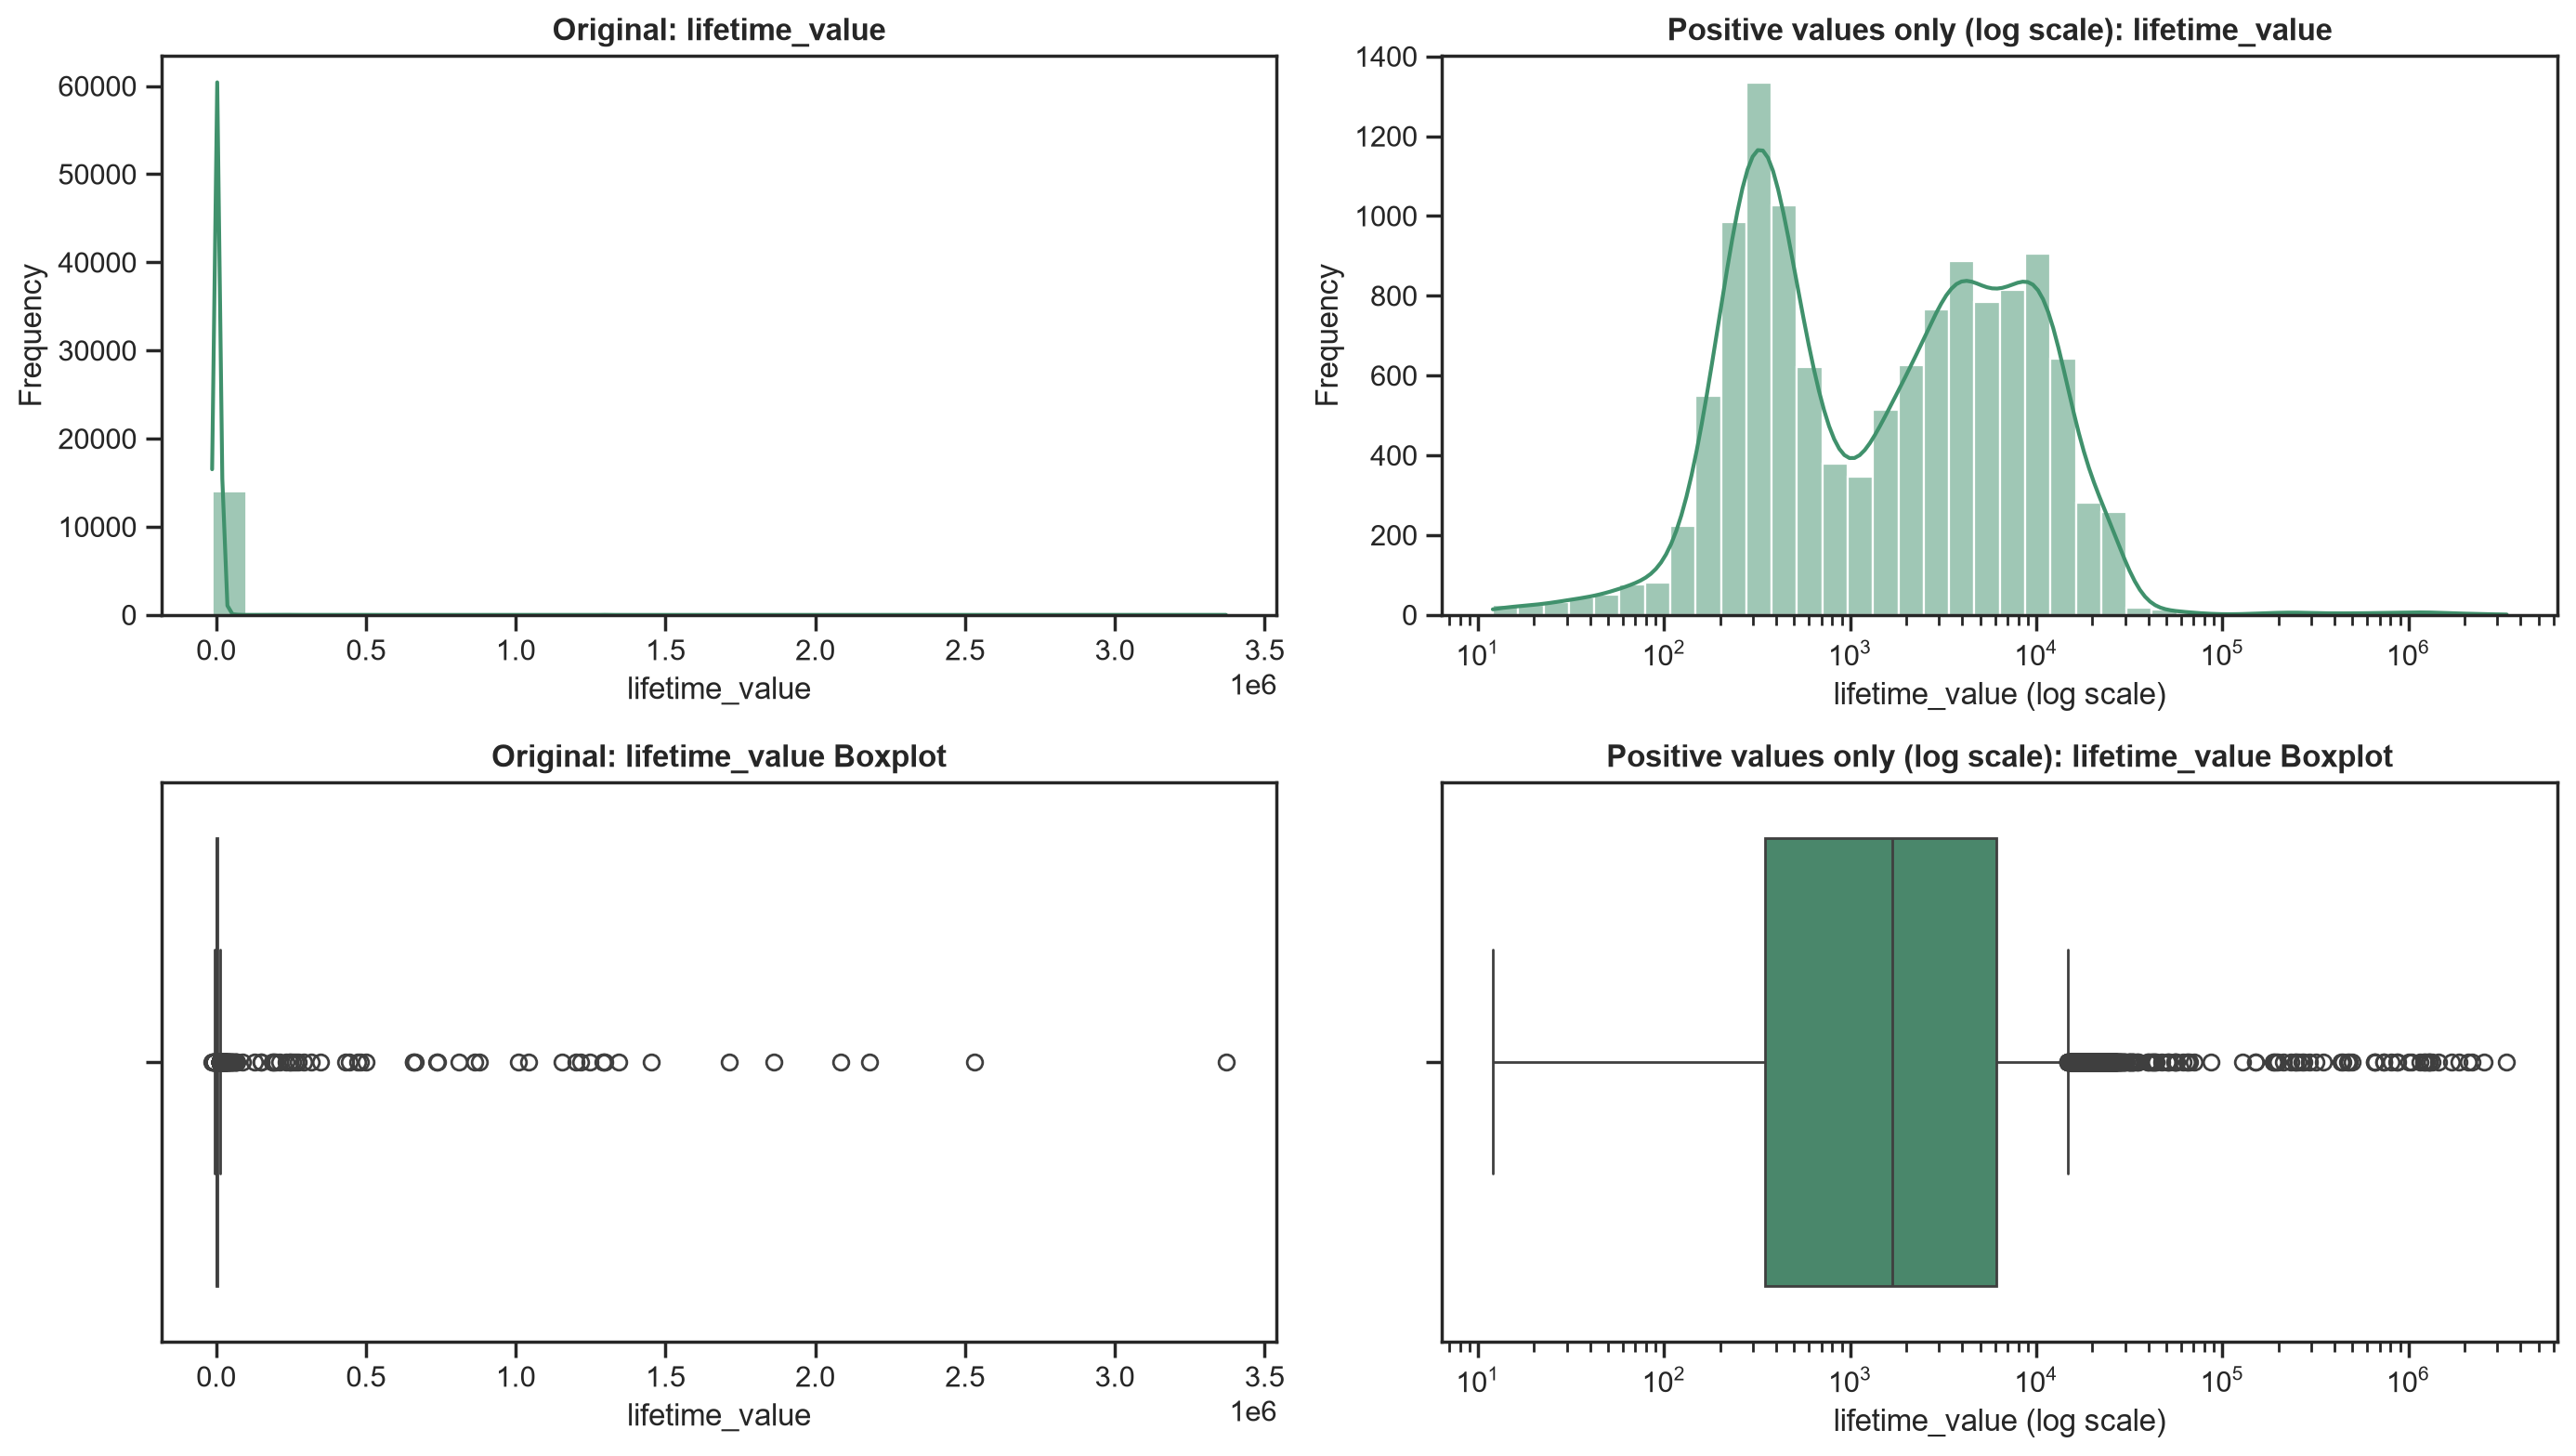

In [43]:
#melhorar visualização
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_ltv_pos = df_nodups[df_nodups["lifetime_value"] > 0]

sns.histplot(df_nodups["lifetime_value"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_ltv_pos["lifetime_value"], bins=40, log_scale=True, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["lifetime_value"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_ltv_pos["lifetime_value"], color=main_color, ax=axes[1, 1])
axes[1, 1].set_xscale("log")

axes[0, 0].set_title('Original: lifetime_value', fontweight="bold")
axes[0, 0].set_xlabel('lifetime_value')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Positive values only (log scale): lifetime_value', fontweight="bold")
axes[0, 1].set_xlabel('lifetime_value (log scale)')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: lifetime_value Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('lifetime_value')

axes[1, 1].set_title('Positive values only (log scale): lifetime_value Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('lifetime_value (log scale)')

plt.tight_layout()
plt.show()

In [45]:
(df["lifetime_value"]>5.061540e+03).sum()

np.int64(3606)

## 3.2. Correlation Matrix (original)

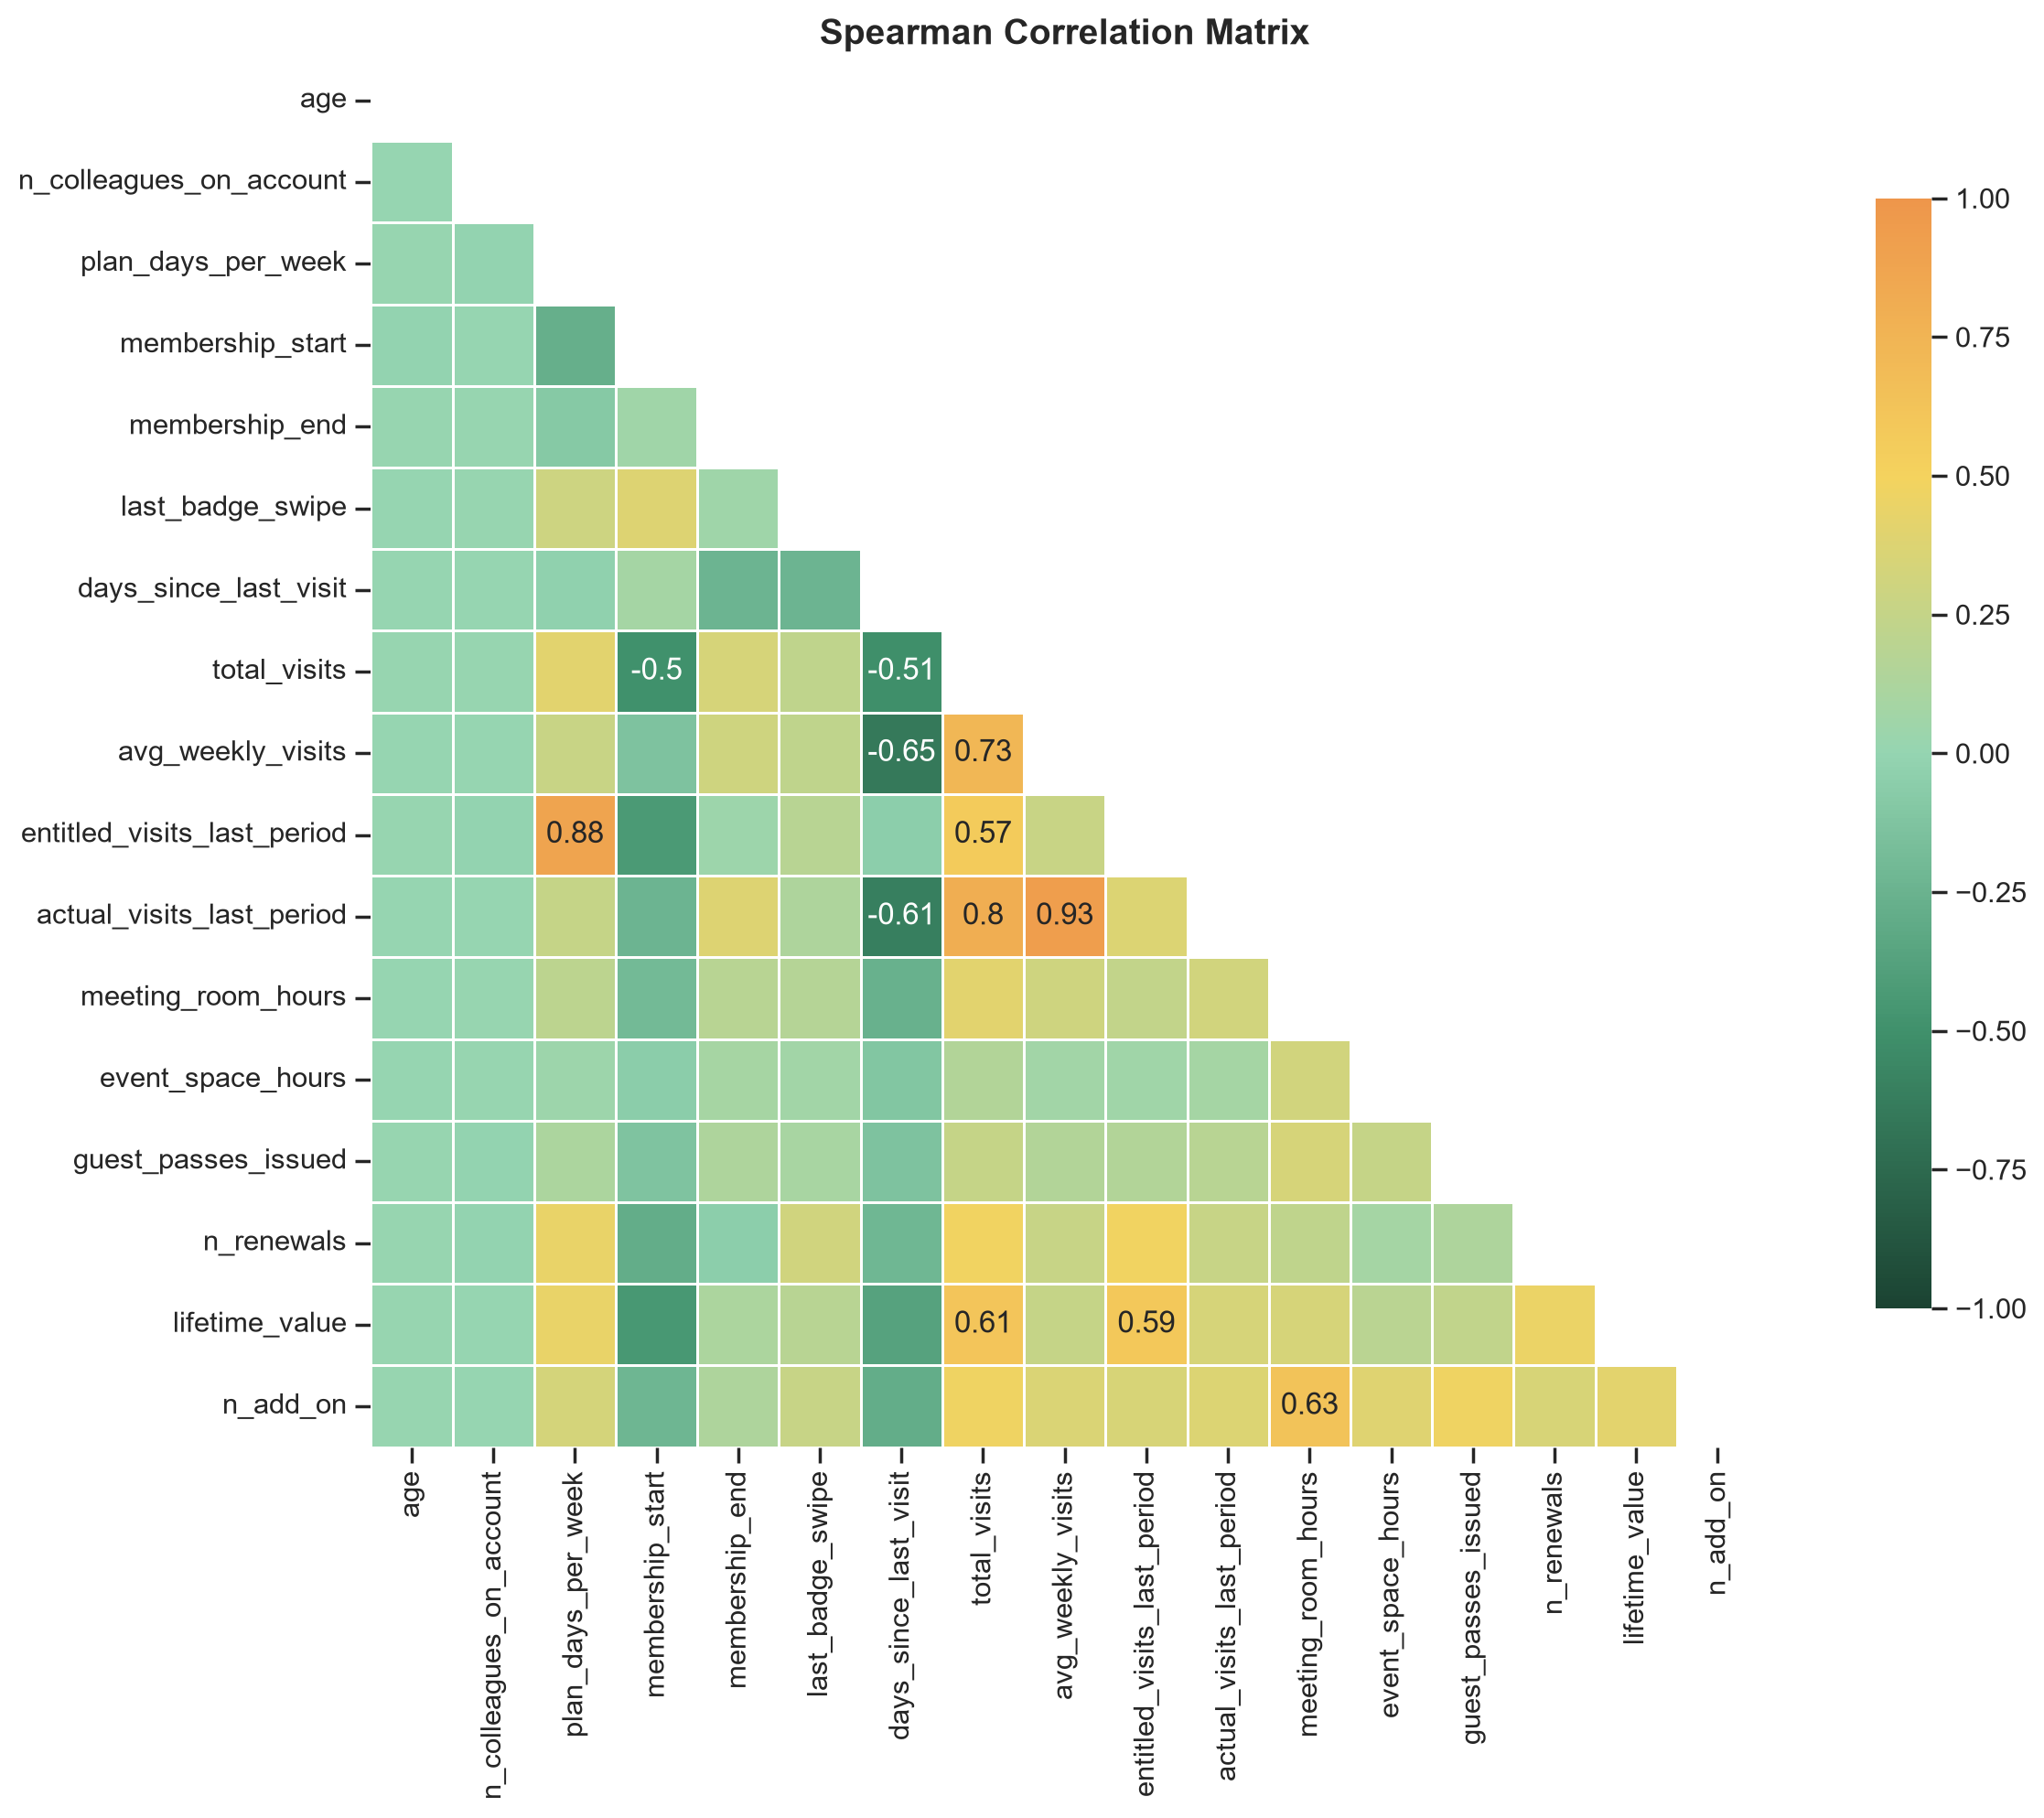

In [49]:
corr = df_nodups[metric_features].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list(
    "smooth_div",
    colors,
    N=256,
)

corr = df_nodups[metric_features].corr(method="spearman").round(2)

# Lógica da aula para anotar apenas correlações fortes (>= 0.5 ou <= -0.5)
mask_annot = np.absolute(corr.values) >= 0.5 
annot = np.where(mask_annot, corr.values, np.full(corr.shape,"")) 

mask_upper = np.triu(np.ones_like(corr, dtype=bool))

fig = plt.figure(figsize=(14, 10))

sns.heatmap(
    data=corr, 
    annot=annot, 
    fmt='s', 
    mask=mask_upper,         
    vmin=-1, vmax=1, 
    center=0, 
    square=True, 
    linewidths=.5, 
    cmap=cmap,              
    cbar_kws={"shrink": .8}   
)

plt.title("Spearman Correlation Matrix", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## 3.3. Bivariate Analysis

### 3.3.1. Contractual Collinearity & Usage

#### 3.3.1.1. `entitled_visits_last_period` and `plan_days_per_week`

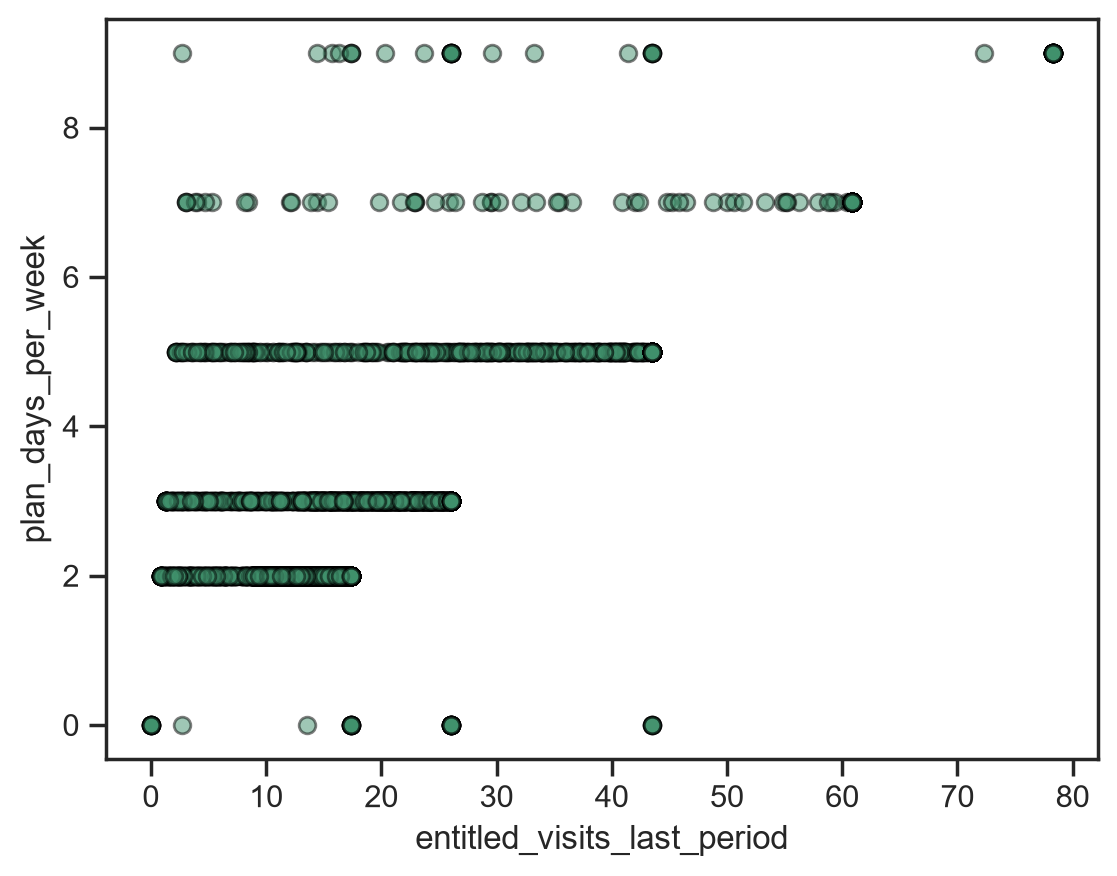

In [50]:
plt.scatter(df_nodups["entitled_visits_last_period"], df_nodups["plan_days_per_week"], 
            edgecolors="black", #
            alpha=.5,
            color = main_color
           )

plt.xlabel("entitled_visits_last_period")
plt.ylabel("plan_days_per_week")

plt.show()

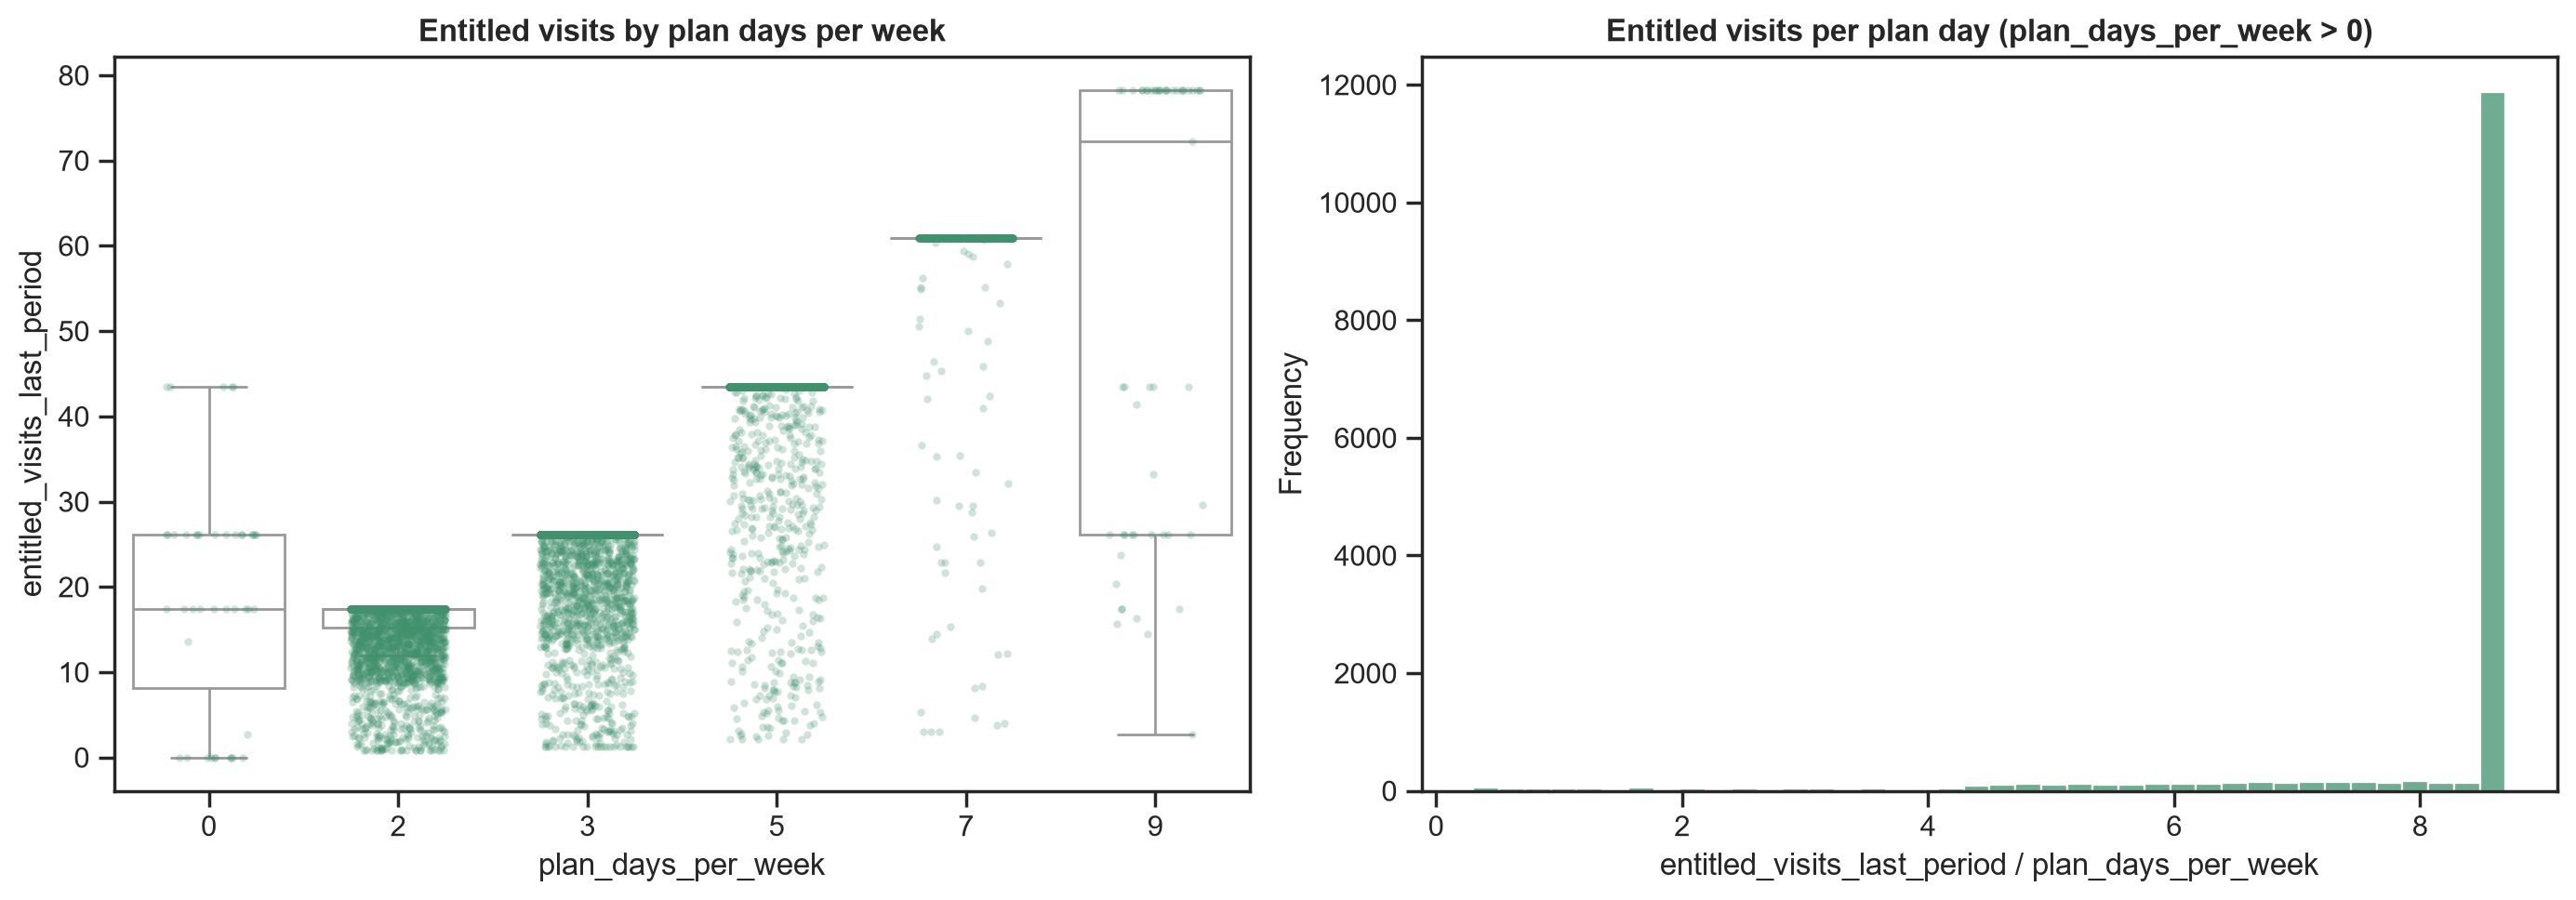

In [51]:
d = df_nodups.dropna(subset=["entitled_visits_last_period", "plan_days_per_week"]).copy()
d_pos = d[d["plan_days_per_week"] > 0].copy()
d_pos["entitled_per_plan_day"] = d_pos["entitled_visits_last_period"] / d_pos["plan_days_per_week"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=d, x="plan_days_per_week", y="entitled_visits_last_period",
            color="white", showfliers=False, ax=axes[0])
sns.stripplot(data=d, x="plan_days_per_week", y="entitled_visits_last_period",
              color=main_color, alpha=0.25, size=3, jitter=0.25, ax=axes[0])
axes[0].set_title('Entitled visits by plan days per week', fontweight="bold")
axes[0].set_xlabel('plan_days_per_week')
axes[0].set_ylabel('entitled_visits_last_period')

sns.histplot(d_pos["entitled_per_plan_day"], bins=40, color=main_color, ax=axes[1])
axes[1].set_title('Entitled visits per plan day (plan_days_per_week > 0)', fontweight="bold")
axes[1].set_xlabel('entitled_visits_last_period / plan_days_per_week')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

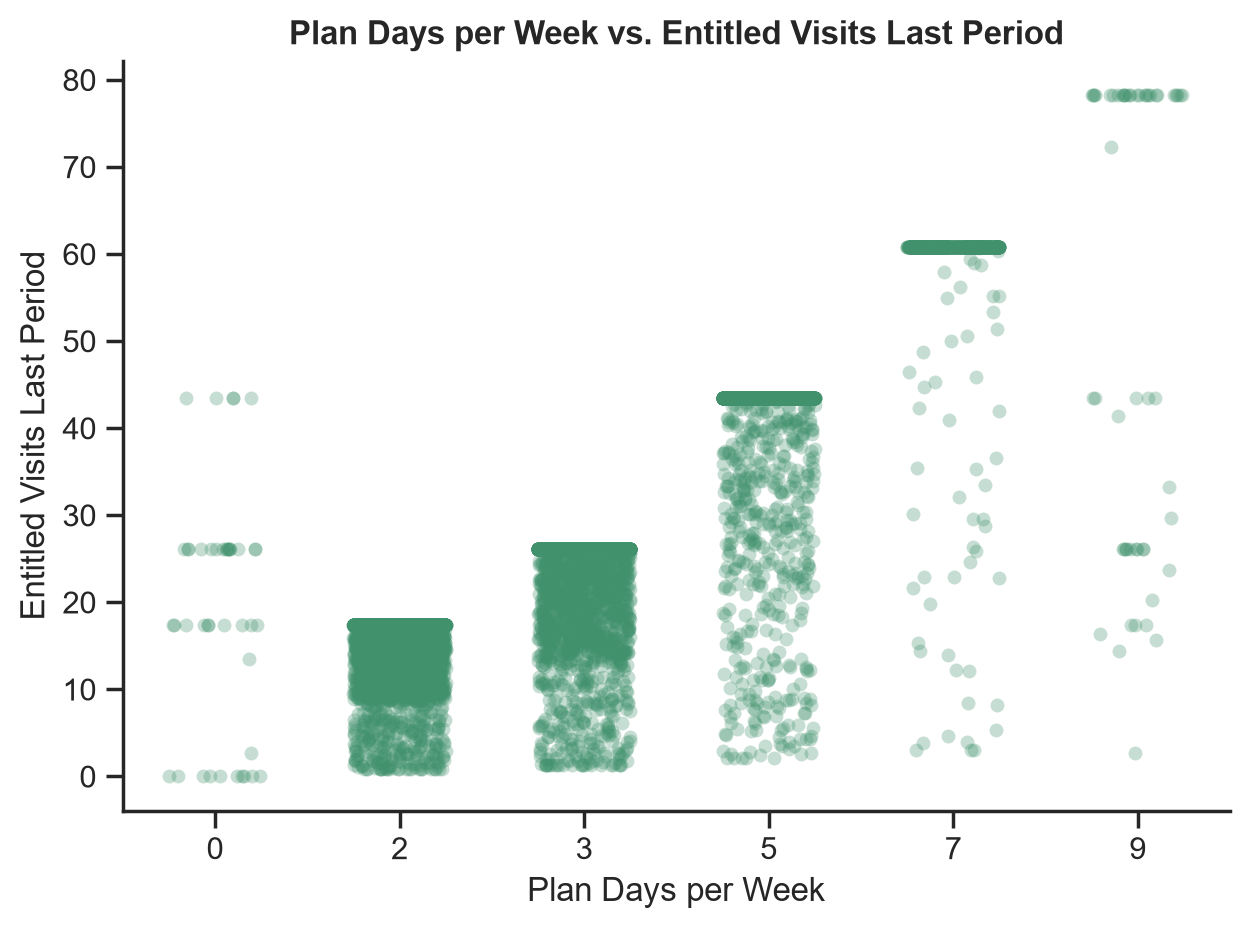

In [52]:
# VER SE QUEREMOS MANTER


# Usar stripplot com jitter para ver a densidade real sem escala logarítmica
sns.stripplot(
    data=df_nodups,
    x="plan_days_per_week",
    y="entitled_visits_last_period",
    color=main_color,
    jitter=0.25,
    alpha=0.3,
    size=5
)

plt.title("Plan Days per Week vs. Entitled Visits Last Period", fontweight="bold")
plt.xlabel("Plan Days per Week")
plt.ylabel("Entitled Visits Last Period")

sns.despine()
plt.tight_layout()
plt.show()

The strong collinearity ($r_s = 0.88$) is confirmed, demonstrating that entitled visits are deterministically tied to the contracted weekly allowance. To prevent double-weighting this contractual dimension, one of these features should be dropped prior to clustering.

#### 3.3.1.2. `actual_visits_last_period` and `entitled_visits_last_period`

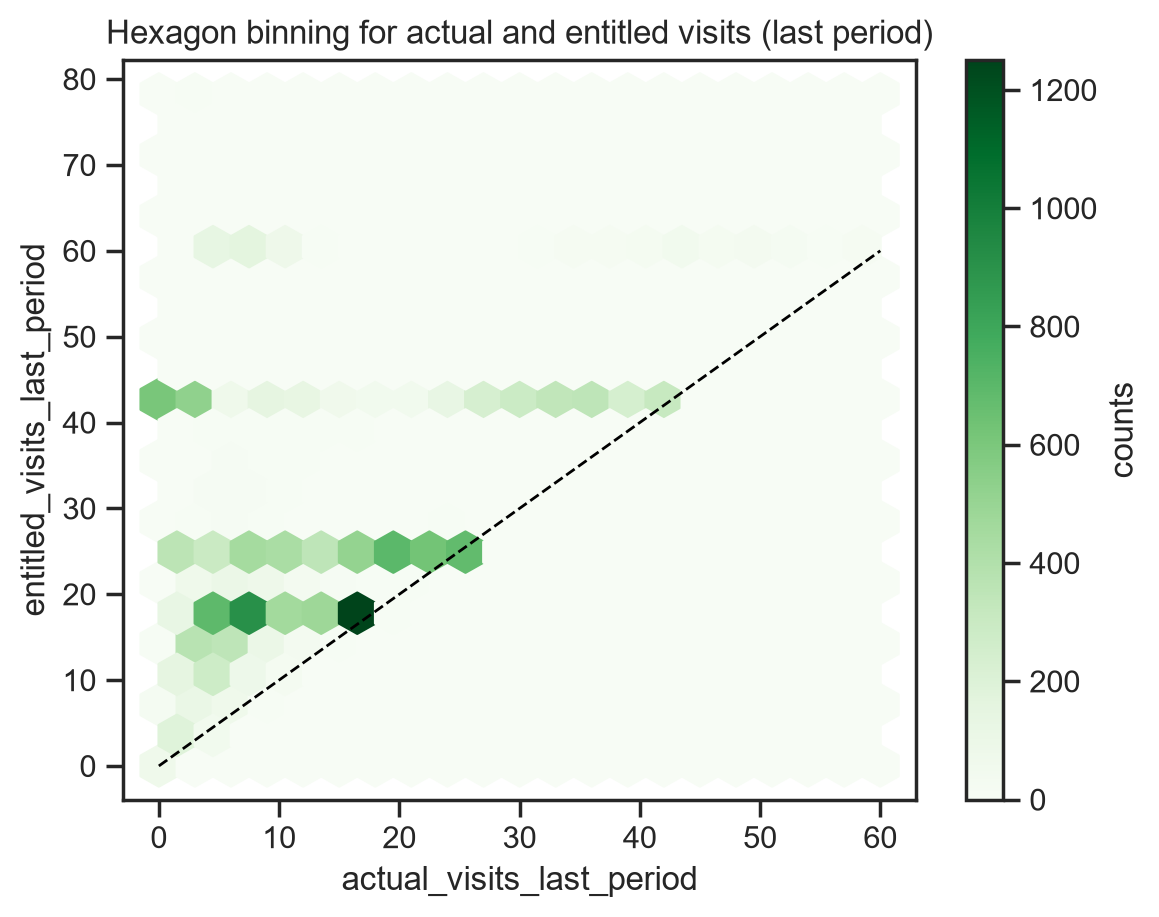

In [54]:
#VER SE É PARA MANTER
sns.set_style('ticks')

fig, ax = plt.subplots()

hb = ax.hexbin(df_nodups["actual_visits_last_period"], df_nodups["entitled_visits_last_period"], 
                gridsize=20,
               cmap='Greens'
              )

ax.plot([0, 60], [0, 60], color="black", linestyle="--", linewidth=1)

ax.set_title("Hexagon binning for actual and entitled visits (last period)")
cb = fig.colorbar(hb, ax=ax, label='counts')

plt.xlabel("actual_visits_last_period")
plt.ylabel("entitled_visits_last_period")
plt.show()

A linha tracejada representa o uso pleno do plano, isto é, o caso em que o número de visitas realizadas coincide com o número de visitas a que o cliente tem direito. Como cada cliente não pode ultrapassar o seu direito, os hexágonos situam-se praticamente todos sobre a linha ou à sua esquerda (à direita seria quase impossível). Uma parte importante dos clientes encontra-se à esquerda da linha, o que indica que utilizam apenas parte do plano. No entanto, o hexágono mais denso (cerca de 16 a 17 visitas realizadas, para um direito de cerca de 17) está junto à linha, o que mostra que há também um grupo relevante de clientes que o usa praticamente na totalidade.

Destaca-se ainda um grupo de cerca de 1.300 clientes com plano de 5 dias (direito de cerca de 43 visitas) que não realizaram praticamente nenhuma visita no último período. Esta concentração poderá corresponder aos registos com o código 999 em `days_since_last_visit` identificados anteriormente, o que indicaria que se trata de registos incompletos e não de clientes que efetivamente não utilizam o plano:

In [56]:
d = df_nodups.dropna(subset=["actual_visits_last_period", "entitled_visits_last_period"])
mask = (d["actual_visits_last_period"] <= 5) & (d["entitled_visits_last_period"].between(40, 45))

print("Customers in the circled area:", mask.sum())
print("Share with days_since_last_visit == 999:", (d.loc[mask, "days_since_last_visit"] == 999).mean().round(3))
d.loc[mask, "lifetime_value"].describe().round(1)

Customers in the circled area: 1168
Share with days_since_last_visit == 999: 0.133


count      1064.0
mean       7761.1
std       26164.0
min      -11948.6
25%        4692.0
50%        7580.5
75%        9655.6
max      734531.0
Name: lifetime_value, dtype: float64

Apenas cerca de 13% destes clientes têm o código 999 em `days_since_last_visit` e o seu `lifetime_value` é semelhante ao de um cliente típico (mediana de cerca de 7.600), pelo que não parecem ser registos incompletos, mas sim clientes que pagam um plano elevado e o utilizam muito pouco. Este poderá ser um segmento relevante para a segmentação (por exemplo, clientes em risco de abandono), a analisar mais à frente.

#### 3.3.1.3. `avg_weekly_visits` and `plan_days_per_week`

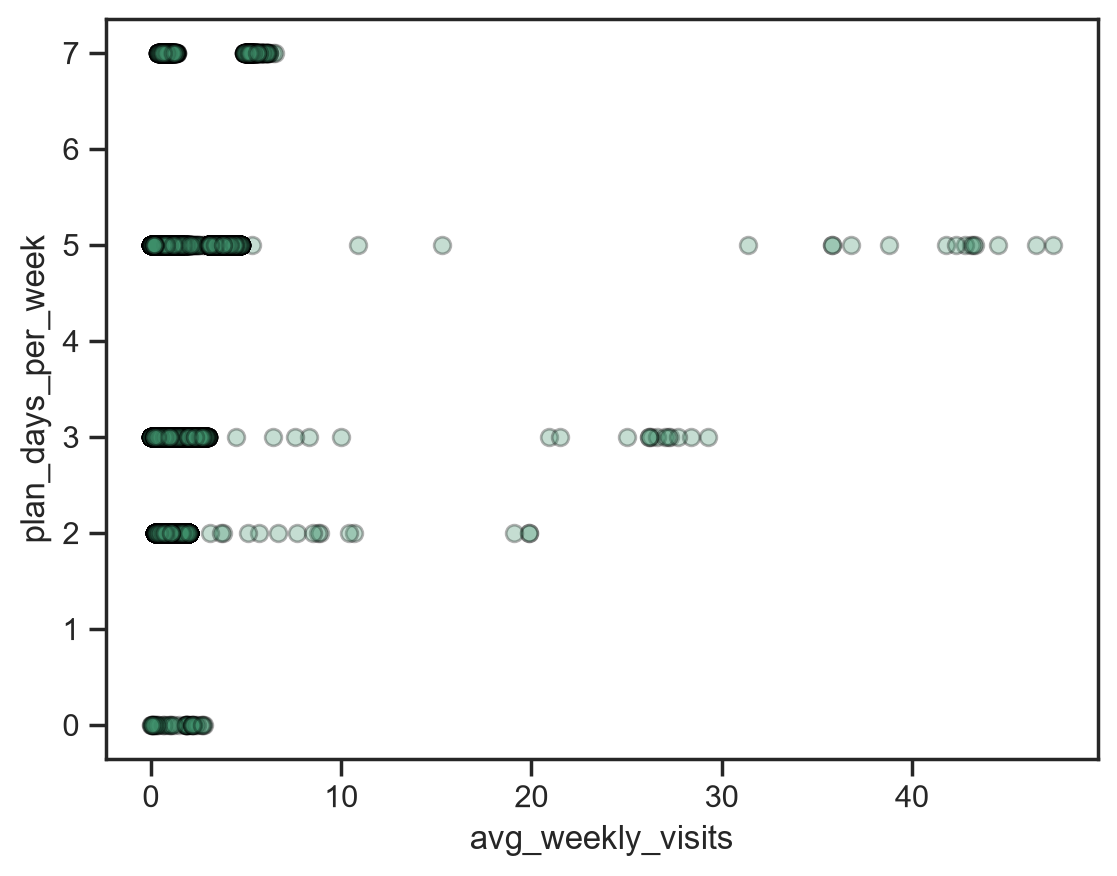

In [57]:
df_filtered = df_nodups[df_nodups["plan_days_per_week"] <= 7]
plt.scatter(df_filtered["avg_weekly_visits"], df_filtered["plan_days_per_week"], 
            edgecolors="black",
            alpha=.3,
            color = main_color
           )

plt.xlabel("avg_weekly_visits")
plt.ylabel("plan_days_per_week")

plt.show()

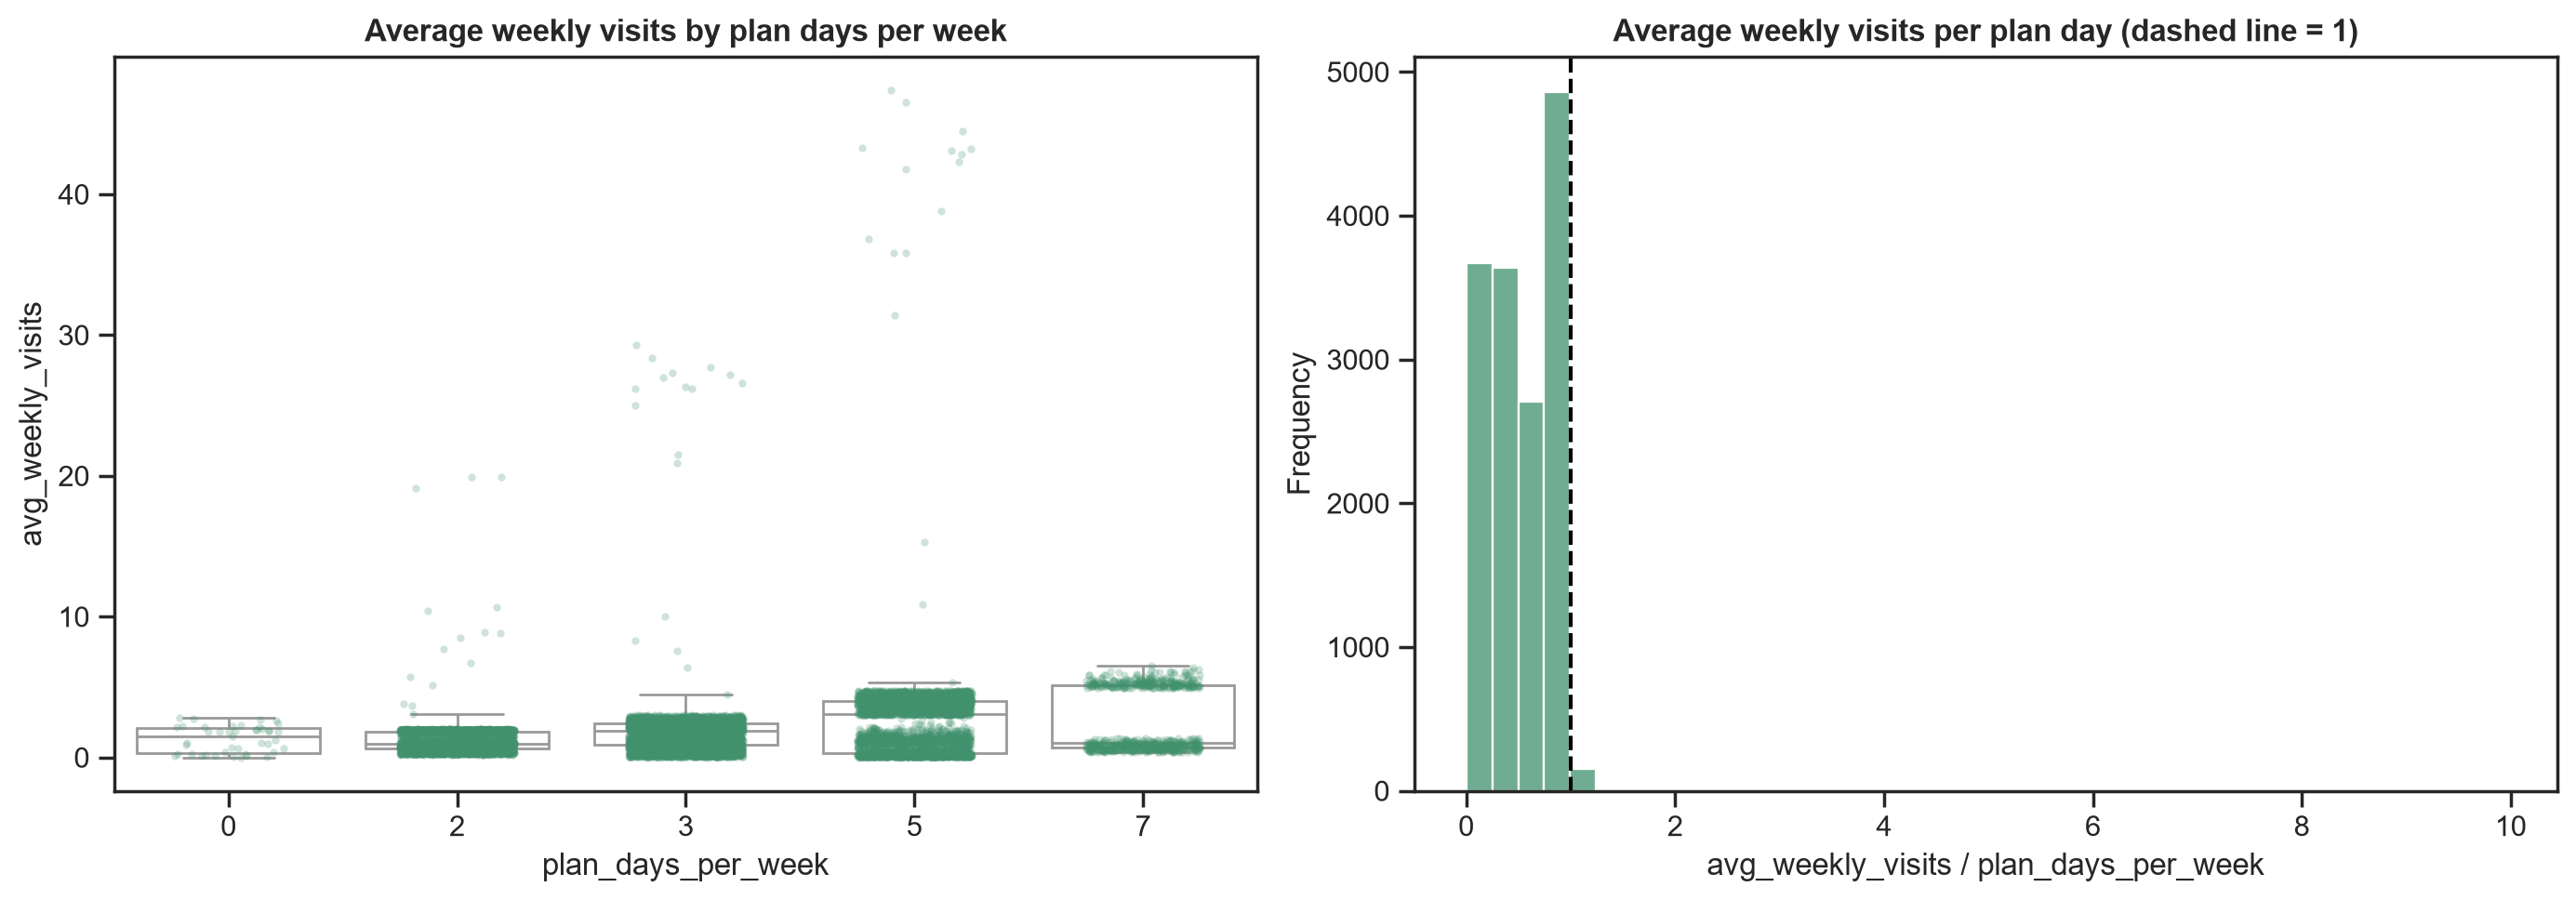

In [59]:
d = df_nodups[df_nodups["plan_days_per_week"] <= 7].dropna(subset=["avg_weekly_visits", "plan_days_per_week"]).copy()
d_pos = d[d["plan_days_per_week"] > 0].copy()
d_pos["visits_per_plan_day"] = d_pos["avg_weekly_visits"] / d_pos["plan_days_per_week"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=d, x="plan_days_per_week", y="avg_weekly_visits", color="white", showfliers=False, ax=axes[0])
sns.stripplot(data=d, x="plan_days_per_week", y="avg_weekly_visits", color=main_color,
              alpha=0.25, size=3, jitter=0.25, ax=axes[0])
axes[0].set_title('Average weekly visits by plan days per week', fontweight="bold")
axes[0].set_xlabel('plan_days_per_week')
axes[0].set_ylabel('avg_weekly_visits')

sns.histplot(d_pos["visits_per_plan_day"], bins=40, color=main_color, ax=axes[1])
axes[1].axvline(1, color="black", linestyle="--")
axes[1].set_title('Average weekly visits per plan day (dashed line = 1)', fontweight="bold")
axes[1].set_xlabel('avg_weekly_visits / plan_days_per_week')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

#### 3.3.1.4. `total_visits` and `entitled_visits_last_period`

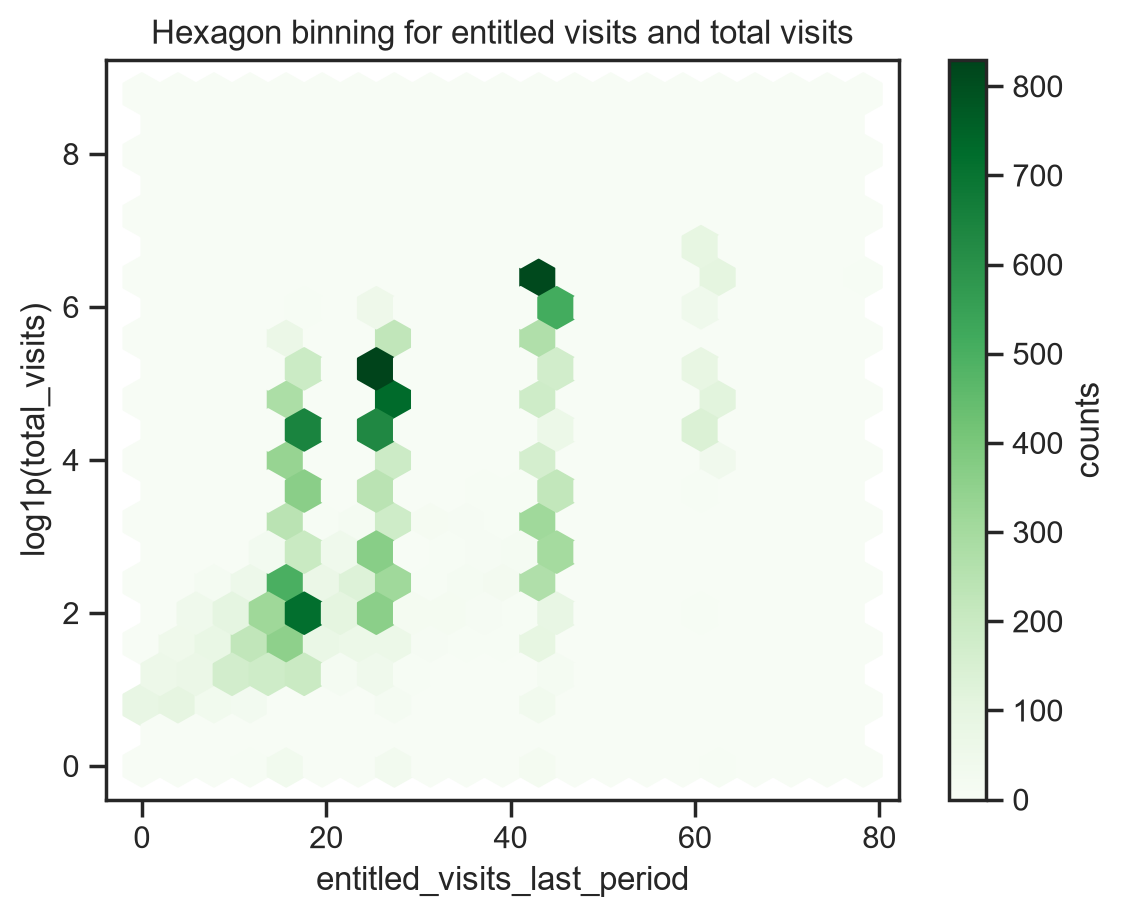

In [58]:
# VER SE É PARA MANTER


sns.set_style('ticks')

fig, ax = plt.subplots()

subset = df_nodups[["entitled_visits_last_period", "total_visits"]].dropna()
subset = subset[subset["total_visits"] >= 0]

hb = ax.hexbin(subset["entitled_visits_last_period"], np.log1p(subset["total_visits"]), 
                gridsize=20,
               cmap='Greens'
              )

ax.set_title("Hexagon binning for entitled visits and total visits")
cb = fig.colorbar(hb, ax=ax, label='counts')

plt.xlabel("entitled_visits_last_period")
plt.ylabel("log1p(total_visits)")
plt.show()

#### 3.3.1.5. `usage_rate`

In [ ]:
#VER SE É PARA MANTER


sns.set_style("ticks")
df_nodups.loc[:, "usage_rate"] = (
    df_nodups["actual_visits_last_period"] 
    / df_nodups["entitled_visits_last_period"].replace(0, np.nan)
)
sns.histplot(df_nodups['usage_rate'].dropna(), bins=20, kde=True, color = main_color)

plt.title('Distribution of Usage Rate (actual / entitled visits)')
plt.xlabel('Usage Rate')
plt.ylabel('Frequency')
plt.show()

### 3.3.2. Recency vs. Frequency

#### 3.3.2.1. `days_since_last_visit` and `avg_weekly_visits`

In [ ]:
filtered_df = df_nodups[df_nodups["days_since_last_visit"] > 0]

plt.scatter(filtered_df["days_since_last_visit"], filtered_df["avg_weekly_visits"], 
            edgecolors="black", 
            alpha=.5,
            color = main_color
           )

plt.xlabel("days_since_last_visit")
plt.ylabel("avg_weekly_visits")

plt.show()

#### 3.3.2.2. `actual_visits_last_period` and `avg_weekly_visits` , `total_visits` and `actual_visits_last_period`,  `total_visits` and `avg_weekly_visits` 

In [ ]:
# VER SE É PARA MANTER





sns.set_style('ticks')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. actual vs avg_weekly
subset1 = df_nodups[["actual_visits_last_period", "avg_weekly_visits"]].dropna()
subset1 = subset1[(subset1["actual_visits_last_period"] >= 0) & (subset1["avg_weekly_visits"] >= 0)]
ax = axes[0]
hb = ax.hexbin(np.log1p(subset1["actual_visits_last_period"]), np.log1p(subset1["avg_weekly_visits"]), 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title("Hexagon binning for actual visits and avg weekly visits")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("log1p(actual_visits_last_period)")
ax.set_ylabel("log1p(avg_weekly_visits)")

# 2. total_visits vs actual
subset2 = df_nodups[["total_visits", "actual_visits_last_period"]].dropna()
subset2 = subset2[(subset2["total_visits"] >= 0) & (subset2["actual_visits_last_period"] >= 0)]
ax = axes[1]
hb = ax.hexbin(np.log1p(subset2["total_visits"]), np.log1p(subset2["actual_visits_last_period"]), 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title("Hexagon binning for total visits and actual visits")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("log1p(total_visits)")
ax.set_ylabel("log1p(actual_visits_last_period)")

# 3. total_visits vs avg_weekly
subset3 = df_nodups[["total_visits", "avg_weekly_visits"]].dropna()
subset3 = subset3[(subset3["total_visits"] >= 0) & (subset3["avg_weekly_visits"] >= 0)]
ax = axes[2]
hb = ax.hexbin(np.log1p(subset3["total_visits"]), np.log1p(subset3["avg_weekly_visits"]), 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title("Hexagon binning for total visits and avg weekly visits")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("log1p(total_visits)")
ax.set_ylabel("log1p(avg_weekly_visits)")

plt.tight_layout()
plt.show()

#### 3.3.2.3. `days_since_last_visit` and `actual_visits_last_period`, `days_since_last_visit` vs `total_visits`

In [ ]:
# VER SE É PARA MANTER


sns.set_style('ticks')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. days_since_last_visit vs actual
subset1 = df_nodups[["days_since_last_visit", "actual_visits_last_period"]].dropna()
subset1 = subset1[(subset1["days_since_last_visit"] >= 0) & (subset1["actual_visits_last_period"] >= 0)]
ax = axes[0]
hb = ax.hexbin(np.log1p(subset1["days_since_last_visit"]), np.log1p(subset1["actual_visits_last_period"]), 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title("Hexagon binning for days since last visit and actual visits")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("log1p(days_since_last_visit)")
ax.set_ylabel("log1p(actual_visits_last_period)")

# 2. days_since_last_visit vs total_visits
subset2 = df_nodups[["days_since_last_visit", "total_visits"]].dropna()
subset2 = subset2[(subset2["days_since_last_visit"] >= 0) & (subset2["total_visits"] >= 0)]
ax = axes[1]
hb = ax.hexbin(np.log1p(subset2["days_since_last_visit"]), np.log1p(subset2["total_visits"]), 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title("Hexagon binning for days since last visit and total visits")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("log1p(days_since_last_visit)")
ax.set_ylabel("log1p(total_visits)")

plt.tight_layout()
plt.show()

### 3.3.3. Monetary Relationships

#### 3.3.3.1. `lifetime_value` and `total_visits`
To improve visualization, since there are a lot of high values in both variables, we transformed both axes to a logarithmic scale.

In [ ]:
plt.scatter(df_nodups["lifetime_value"], df_nodups["total_visits"], 
            edgecolors="black", 
            alpha=.5,
            color = main_color
           )

plt.xscale('log')
plt.yscale('log')

plt.xlabel("lifetime_value")
plt.ylabel("total_visits")

plt.show()

#### 3.3.3.2. `entitled_visits_last_period` and `lifetime_value` vs `actual_visits_last_period` and `lifetime_value`

In [ ]:
sns.set_style('ticks')

subset = df_nodups[
    (df_nodups["lifetime_value"] > 0) & 
    (df_nodups["entitled_visits_last_period"] > 0) & 
    (df_nodups["actual_visits_last_period"] > 0)
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Entitled Visits vs Lifetime Value 
ax1.scatter(
    subset["entitled_visits_last_period"], 
    subset["lifetime_value"],
    color=main_color,
    alpha=0.35,
    edgecolors="none",
    s=25
)
ax1.set_yscale('log')
ax1.set_title("Entitled Visits (Contracted) vs. Lifetime Value", fontweight="bold")
ax1.set_xlabel("entitled_visits_last_period")
ax1.set_ylabel("lifetime_value (log scale)")

# Actual Visits vs Lifetime Value 
ax2.scatter(
    subset["actual_visits_last_period"], 
    subset["lifetime_value"],
    color=main_color,
    alpha=0.35,
    edgecolors="none",
    s=25
)
ax2.set_yscale('log')
ax2.set_title("Actual Visits (Consumed) vs. Lifetime Value", fontweight="bold")
ax2.set_xlabel("actual_visits_last_period")

sns.despine()
plt.tight_layout()
plt.show()

#### 3.3.3.3. `n_colleagues_on_account` and `lifetime_value`

In [ ]:
plt.scatter(df_nodups["n_colleagues_on_account"], df_nodups["lifetime_value"], 
            edgecolors="black", 
            alpha=.5,
            color = main_color
           )

plt.yscale('log')

plt.xlabel("n_colleagues_on_account")
plt.ylabel("lifetime_value")

plt.show()

#### 3.3.3.4. `ltv_per_visit`

In [ ]:
#VER SE É PARA MANTER



df_nodups.loc[:, "ltv_per_visit"] = (df_nodups["lifetime_value"]
                            / df_nodups["total_visits"].replace(0, np.nan))
ltv_clean = df_nodups['ltv_per_visit'].dropna()
ltv_clean = ltv_clean[ltv_clean >= 0]
sns.histplot(np.log1p(ltv_clean), bins=30, kde=True, color = main_color)

plt.title('Distribution of Lifetime Value per Visit (log1p)')
plt.xlabel('log1p(ltv_per_visit)')
plt.ylabel('Frequency')
plt.show()


#Os 1725 membros com lifetime_value = 0. 
#Dão ltv_per_visit = 0, e com log1p ficam todos num pico em 0. Esse pico não é um grupo de “visitas baratas”, é gente que não gerou receita.

### 3.3.4. Facility Usage & Cross-Selling

#### 3.3.4.1. `total_visits` and `meeting_room_hours` vs `total_visits` and `event_space_hours`

In [ ]:
sns.set_style('ticks')

subset = df_nodups[(df_nodups["total_visits"] > 0) & 
            (df_nodups["meeting_room_hours"] > 0) & 
            (df_nodups["event_space_hours"] > 0)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# Total Visits vs. Meeting Room Hours
hb1 = ax1.hexbin(subset["total_visits"], subset["meeting_room_hours"], 
                 gridsize=20,
                 cmap='Greens',
                 xscale='log',
                 yscale='log',
                 bins='log',
                 mincnt=1
                )
ax1.set_title("Total Visits vs Meeting Room Hours")
ax1.set_xlabel("total_visits")
ax1.set_ylabel("meeting_room_hours")
cb1 = fig.colorbar(hb1, ax=ax1, label='counts (log scale)')

# Total Visits vs. Event Space Hours
hb2 = ax2.hexbin(subset["total_visits"], subset["event_space_hours"], 
                 gridsize=20,
                 cmap='Greens',
                 xscale='log',
                 yscale='log',
                 bins='log',
                 mincnt=1
                )
ax2.set_title("Total Visits vs Event Space Hours")
ax2.set_xlabel("total_visits")
ax2.set_ylabel("event_space_hours")
cb2 = fig.colorbar(hb2, ax=ax2, label='counts (log scale)')

plt.tight_layout()
plt.show()

#### 3.3.4.2. `meeting_room_hours` and `event_space_hours`

In [ ]:
plt.scatter(df_nodups["meeting_room_hours"], df_nodups["event_space_hours"], 
            edgecolors="black",
            alpha=.5,
            color = main_color
           )

plt.xlabel("meeting_room_hours")
plt.ylabel("event_space_hours")

plt.show()

### 3.3.5. `age`

#### 3.3.5.1. `age` vs `lifetime_value`, `age` vs `plan_days_per_week`

In [ ]:
#VER SE É PARA MANTER



sns.set_style('ticks')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_age = df_nodups[(df_nodups["age"] > 17) & (df_nodups["age"] < 89)]

# age vs lifetime_value
subset1 = df_age[["age", "lifetime_value"]].dropna()
subset1 = subset1[(subset1["age"] >= 0) & (subset1["lifetime_value"] >= 0)]
ax = axes[0]
hb = ax.hexbin(subset1["age"], np.log1p(subset1["lifetime_value"]), 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title(f"Hexagon binning for age and lifetime value,\ncorr = {subset1.corr(method='spearman').values[0,1].round(2)}")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("age")
ax.set_ylabel("log1p(lifetime_value)")

# age vs plan_days_per_week
subset2 = df_age[df_age["plan_days_per_week"] <= 7][["age", "plan_days_per_week"]].dropna()
subset2 = subset2[(subset2["age"] >= 0) & (subset2["plan_days_per_week"] >= 0)]
ax = axes[1]
hb = ax.hexbin(subset2["age"], subset2["plan_days_per_week"], 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title(f"Hexagon binning for age and plan days per week,\ncorr = {subset2.corr(method='spearman').values[0,1].round(2)}")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("age")
ax.set_ylabel("plan_days_per_week")

plt.tight_layout()
plt.show()

### 3.3.6 Pairplot

In [ ]:
#VER SE É PARA MANTER E MUDAR A COR

df_clean_pair = df_nodups[
    (df_nodups["plan_days_per_week"] >= 0) & 
    (df_nodups["actual_visits_last_period"] >= 0) & 
    (df_nodups["avg_weekly_visits"] >= 0) & 
    (df_nodups["days_since_last_visit"] >= 0) & 
    (df_nodups["total_visits"] >= 0) & 
    (df_nodups["lifetime_value"] >= 0)
]

df_pair = pd.DataFrame({
    "plan_days_per_week": df_clean_pair["plan_days_per_week"],
    "actual_visits_last_period": df_clean_pair["actual_visits_last_period"],
    "log1p_avg_weekly_visits": np.log1p(df_clean_pair["avg_weekly_visits"]),
    "log1p_days_since_last_visit": np.log1p(df_clean_pair["days_since_last_visit"]),
    "log1p_total_visits": np.log1p(df_clean_pair["total_visits"]),
    "log1p_lifetime_value": np.log1p(df_clean_pair["lifetime_value"]),
}).sample(2000, random_state=42)

sns.set()

g = sns.pairplot(df_pair, diag_kind="hist", plot_kws={"color": main_color}, diag_kws={"color": main_color})

plt.subplots_adjust(top=0.95)
plt.suptitle("Pairwise Relationship of Numerical Variables", fontsize=20)
plt.show()

## 3.2. Correlation Matrix (com as novas variveis)

In [ ]:
corr = df_nodups[metric_features + ["usage_rate", "ltv_per_visit"]].corr(method="spearman").round(2)

mask_annot = np.absolute(corr.values) >= 0.5 
annot = np.where(mask_annot, corr.values, np.full(corr.shape,"")) 

mask_upper = np.triu(np.ones_like(corr, dtype=bool))

fig = plt.figure(figsize=(14, 10))

sns.heatmap(
    data=corr, 
    annot=annot, 
    fmt='s', 
    mask=mask_upper,         
    vmin=-1, vmax=1, 
    center=0, 
    square=True, 
    linewidths=.5, 
    cmap=cmap,              
    cbar_kws={"shrink": .8}   
)

plt.title("Spearman Correlation Matrix", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

Comparing the variables where correlation is bigger than 0.5 and less than -0.5

<b><font size="5" color="#FAA85E">3.3. Bivariate Analysis</font></b><br>

In [ ]:
cmap_palette = LinearSegmentedColormap.from_list("custom", colors, N=256)
palette = [cmap_palette(i) for i in np.linspace(0, 1, 11)]


log_metric = df_pair.columns

pairs = list(combinations(log_metric, 2))

n_cols = 6
n_rows = ceil(len(pairs) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 4 * n_rows))

for ax, (x, y) in zip(axes.flatten(), pairs):
    d = df_pair[[x, y]].dropna()
    xlo, xhi = d[x].quantile([0.01, 0.99])
    ylo, yhi = d[y].quantile([0.01, 0.99])
    d = d[d[x].between(xlo, xhi) & d[y].between(ylo, yhi)]
    hb = ax.hexbin(d[x], d[y], gridsize=35, cmap=cmap_palette, bins="log", mincnt=1)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    fig.colorbar(hb, ax=ax)

plt.tight_layout()
plt.show()

<b><font size="6" color="#FAA85E">4. Date Features Visualization</font></b><br>

In [ ]:
placeholder = pd.Timestamp("1970-01-01")

# só clientes que saíram (sem placeholder) e com datas coerentes
df_tenure = df_nodups.loc[
    (df_nodups["membership_end"] != placeholder) &
    (df_nodups["membership_end"] >= df_nodups["membership_start"])
].copy()

df_tenure["tenure_days"] = (df_tenure["membership_end"] - df_tenure["membership_start"]).dt.days

print(f"Customers analysed: {len(df_tenure)} of {len(df)}")
print(df_tenure["tenure_days"].describe().round(0))

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(df_tenure["tenure_days"], bins=36, color=main_color, edgecolor="white", ax=ax)

median = df_tenure["tenure_days"].median()
ax.axvline(median, color="#F26B4E", linewidth=2.5, linestyle="--")
ax.annotate(f"Median: {median:.0f} days", xy=(median, ax.get_ylim()[1] * 0.92),
            xytext=(10, 0), textcoords="offset points", color="#F26B4E", fontweight="bold")

ax.set_title("Membership duration (customers who left)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Days between membership_start and membership_end")
ax.set_ylabel("Number of customers")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df_tenure, x="plan_tier", y="tenure_days", order=tier_order,
            color=main_color, ax=ax)

ax.set_title("Membership duration by plan tier", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Duration (days)")
ax.tick_params(axis="x", rotation=20)
sns.despine()
plt.tight_layout()
plt.show()

df_tenure.groupby("plan_tier")["tenure_days"].describe().loc[tier_order].round(0)

`dedicated_desk` and `private_office` are the plans with the longest-lasting customers (median duration of about 817 and 863 days, respectively), while `full_time` is the most heterogeneous plan, with durations spread widely (IQR from 83 to 660 days), possibly reflecting a group of customers who leave quickly alongside a larger group who stay much longer.

`hot_desk` has the shortest durations, with a strongly right-skewed distribution: half of the customers who left did so within 87 days, far below the median of `flex` (279 days), despite both plans having a similar number of customers who left (4,361 vs. 4,207).

These durations only cover customers who already left, and cheaper plans have more recent starts, so absolute values are likely underestimated for them.

In [ ]:
# df_tenure vem da célula anterior (clientes que saíram, datas coerentes)
df_ren = df_tenure[df_tenure["n_renewals"] >= 0].copy()

df_ren["tenure_bin"] = pd.cut(
    df_ren["tenure_days"],
    bins=[0, 90, 180, 365, 540, 730, 900, 1100],
    labels=["≤90", "91–180", "181–365", "366–540", "541–730", "731–900", ">900"]
)

# 1) média de renovações por faixa de duração
mean_by_bin = df_ren.groupby("tenure_bin", observed=True)["n_renewals"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(mean_by_bin.index.astype(str), mean_by_bin.values, color=main_color)
for i, v in enumerate(mean_by_bin.values):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=10)
ax.set_title("Average renewals by membership duration", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Duration (days)")
ax.set_ylabel("Average number of renewals")
sns.despine()
plt.tight_layout()
plt.show()

# 2) o mesmo, por plano
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
by_tier = (df_ren.groupby(["tenure_bin", "plan_tier"], observed=True)["n_renewals"]
           .mean().unstack()[tier_order])

fig, ax = plt.subplots(figsize=(11, 5))
by_tier.plot(ax=ax, marker="o", linewidth=2.5,
             color=colors)
ax.set_title("Average renewals by duration and plan tier", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Duration (days)")
ax.set_ylabel("Average number of renewals")
ax.legend(title="Plan tier", frameon=True, fancybox=True)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
new_per_month = df_nodups.groupby(df_nodups["membership_start"].dt.to_period("M")).size()

plt.figure(figsize=(12, 4))
new_per_month.plot(color=main_color)
plt.title("New memberships per month")
plt.xlabel("")
plt.ylabel("Number of new customers")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# nº de novos clientes por (ano, mês)
tmp = df_nodups.copy()
tmp["year"] = tmp["membership_start"].dt.year
tmp["month"] = tmp["membership_start"].dt.month

pivot = tmp.pivot_table(index="month", columns="year", values="membership_start", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
for color, year in zip(colors, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="black", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("New memberships per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of new customers")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# nº de novos clientes por mês (inclui meses com 0)
monthly = df_nodups.set_index("membership_start").resample("MS").size()

# tendência suavizada (média móvel de 6 meses)
trend = monthly.rolling(6, center=True, min_periods=1).mean()

labels = monthly.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(range(len(monthly)), monthly.values, color=main_color, alpha=0.55, width=0.8)

step = 3
ax.set_xticks(range(0, len(monthly), step))
ax.set_xticklabels(labels[::step], rotation=45, ha="right")

ax.set_title("New memberships per month")
ax.set_xlabel("")
ax.set_ylabel("Number of new customers")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# só saídas reais (exclui o placeholder de 1970)
exits = df_nodups.loc[df_nodups["membership_end"] != pd.Timestamp("1970-01-01"), "membership_end"]

# nº de saídas por mês (inclui meses com 0)
monthly_exit = exits.to_frame().set_index("membership_end").resample("MS").size()

# tendência suavizada (média móvel de 6 meses)
trend_exit = monthly_exit.rolling(6, center=True, min_periods=1).mean()

labels = monthly_exit.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(range(len(monthly_exit)), monthly_exit.values, color=main_color, alpha=0.55, width=0.8)
step = 3
ax.set_xticks(range(0, len(monthly_exit), step))
ax.set_xticklabels(labels[::step], rotation=45, ha="right")

ax.set_title("Membership exits per month")
ax.set_xlabel("")
ax.set_ylabel("Number of exits")
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# só saídas reais (exclui o placeholder de 1970)
tmp = df_nodups.loc[df_nodups["membership_end"] != pd.Timestamp("1970-01-01")].copy()
tmp["year"] = tmp["membership_end"].dt.year
tmp["month"] = tmp["membership_end"].dt.month

# nº de saídas por (ano, mês)
pivot = tmp.pivot_table(index="month", columns="year", values="membership_end", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
for color, year in zip(colors, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="#F26B4E", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Membership exits per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of exits")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

<b><font size="6" color="#FAA85E">5. Categorical Features Visualization</font></b><br>

In this section we built an interactive dashboard to analyze the categorical features and to compare them with the metric features.

In [ ]:
object_features = ["industry", "country", "gender", "plan_tier"]
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
# Stringify dates so the grid can serialize them
df_grid = df_nodups.copy()
for c in date_cols:
    if c in df_grid.columns:
        df_grid[c] = df_grid[c].astype(str)

# Radio buttons: no raw date columns
radio_features = [c for c in metric_features
                  if c not in ["membership_start", "membership_end", "last_badge_swipe"]]

external_stylesheets = ['https://codepen.io/chriddyp/pen/bWLwgP.css']
app = Dash(external_stylesheets=external_stylesheets)

app.layout = html.Div(
    style={
        'backgroundColor': '#F7F9FB',
        'color': '#264653',
        'fontFamily': 'Helvetica, Arial, sans-serif',
        'padding': '20px',
        'minHeight': '100vh',
    },
    children=[
        # Title
        html.Div(className='row app-title', children='My First App with Data, Graph, and Controls',
         style={'textAlign': 'center', 'color': colors[0], 'fontSize': 36,
                'fontWeight': 'bold', 'marginBottom': '20px'}),
        
        # Table
        html.Div(className='row', children=[
            dag.AgGrid(
                rowData=df_grid.to_dict('records'),
                columnDefs=[{"field": i, "filter": True, "sortable": True} for i in df_grid.columns],
                defaultColDef={"resizable": True},
                dashGridOptions={"pagination": True, "paginationPageSize": 15},
                )
                ]),
        
        # Controls row 1: metric + aggregation
        html.Div(className='row', children=[
        html.Div(className='six columns', children=[
            dcc.Dropdown(options=radio_features, value=radio_features[0],
            id='metric-dropdown', clearable=False),
                        ]),
        ]),
        html.Div(className='row', children=[
            dcc.RadioItems(options=['avg', 'sum', 'count'], value='avg',
                           inline=True, id='agg-radio'),
                           ]),
        
        # Controls row 2: grouping + filters
        html.Div(className='row', children=[
            html.Div(className='four columns', children=[
                    dcc.Dropdown(options=object_features, value='industry',
                                id='group-dropdown', clearable=False),
                                ]),
            html.Div(className='four columns', children=[
                dcc.Checklist(options=sorted(df_nodups['plan_tier'].dropna().unique()),
                            value=list(df_nodups['plan_tier'].dropna().unique()),
                            inline=True, id='tier-filter'),
                            ]),
            html.Div(className='four columns', children=[
                dcc.RadioItems(options=['All', 'Team', 'Individual'], value='All',
                            inline=True, id='team-filter'),
                            ]),
                            ]),
            
            # Table + histogram
        html.Div(className='row', children=[
            html.Div(className='seven columns', children=[
                            dcc.Graph(figure={}, id='norm-histo-chart-final')
                        ]),
            html.Div(className='five columns', children=[
                dcc.Graph(figure={}, id='histo-chart-final')
            ]),
        ]),
        
            # Second graph (boxplot)
            html.Div(className='row', children=[
                dcc.Graph(figure={}, id='box-chart')
            ]),
        ],
)


@callback(
        Output('norm-histo-chart-final', 'figure'),
        Output('histo-chart-final', 'figure'),
        Output('box-chart', 'figure'),
        Input('metric-dropdown', 'value'),
        Input('group-dropdown', 'value'),
        Input('tier-filter', 'value'),
        Input('team-filter', 'value'),
        Input('agg-radio', 'value'),
)
def update_graph(col_chosen, group, tiers, team, agg):
    d = df_nodups[df_nodups['plan_tier'].isin(tiers)]
    if team == 'Team':
        d = d[d['is_team_account']]
    elif team == 'Individual':
        d = d[~d['is_team_account']]

    fig1 = px.histogram(d, x=group, y=col_chosen, histfunc=agg,
                    color="plan_tier", barmode="group",
                    color_discrete_sequence=colors)
    fig1.update_layout(template='simple_white')

    fig2 = px.histogram(d, x=group, y=col_chosen, histfunc=agg,
                        color="plan_tier", barmode="stack", barnorm="percent",
                        color_discrete_sequence=colors)
    fig2.update_layout(template='simple_white')

    fig3 = px.box(d, x=group, y=col_chosen, color_discrete_sequence=colors)
    fig3.update_layout(template='simple_white')

    for f in (fig1, fig2, fig3):
        f.update_layout(
        template='simple_white',
        paper_bgcolor='white',       # area around the plot
        plot_bgcolor='white',        # plot area
        font=dict(family='Helvetica', color='#264653', size=13),
        title_font_color=colors[0],
        )
        f.update_xaxes(showgrid=False, linecolor='#264653')
        f.update_yaxes(gridcolor='#E5E5E5')
    return fig1, fig2, fig3


if __name__ == '__main__':
    app.run(debug=True)